# Environment-dependent tropical-cyclone genesis rate
## 1° gridded Poisson model interpreted as a discretized inhomogeneous Poisson point process

This notebook builds a first-generation replacement for:

**phase-conditioned basin frequency → month sampling → empirical/GPI genesis map**

with one fitted environmental rate surface:

\[
N_{iym}\sim \mathrm{Poisson}(\mu_{iym}),\qquad
\mu_{iym}=E_{iym}\lambda_{iym}
\]

and

\[
\log \lambda_{iym}
=
\alpha
+\mathrm{month\ effect}
+\beta_{PI}PI
+\beta_{RH}RH
+\beta_{VWS}VWS
+\beta_{\eta}\eta.
\]

Here \(i\) is a 1° genesis cell, \(y\) the year and \(m\) the month.

The exposure \(E\) explicitly accounts for:

- spherical cell area;
- the fraction of the cell that is eligible ocean;
- month duration.

The fitted expected cell counts \(\mu_i\) simultaneously determine:

1. basin/month storm frequency: \(\Lambda=\sum_i\mu_i\);
2. genesis-location probabilities: \(p_i=\mu_i/\Lambda\).

After a 1° cell is selected, the exact genesis location is sampled uniformly over the **eligible ocean part** of the cell using a 0.1° fine mask. This keeps the downscaling deliberately simple while preventing land genesis.

## 0. Assumptions and inputs

This notebook deliberately starts with one basin (e.g. North Atlantic) and one simple Poisson specification.

Expected inputs:

1. `env_native`: monthly `xarray.Dataset` containing at least:
   - `pi` : thermodynamic potential intensity [m/s]
   - `rh600` : relative humidity at 600 hPa [% or fraction, but consistent]
   - `vws` : 850–200 hPa vertical wind shear magnitude [m/s]
   - `abs_vort850` : absolute vorticity magnitude [s-1]

2. `genesis`: a pandas DataFrame with one row per historical genesis event:
   - `storm_id`
   - `time`
   - `lat`
   - `lon`

The genesis definition must match the simulator target. If the simulator starts storms when they first reach tropical-storm intensity, use that same definition here.

3. `land_gdf`: a reasonably high-resolution land polygon GeoDataFrame (Natural Earth 10m / GSHHG / existing project coastline).

4. `basin_polygon`: the valid basin-water domain. This is important because `~land` alone can leave inland water bodies eligible.

In [1]:
from __future__ import annotations

import calendar
import os
import sys
from pathlib import Path
from dataclasses import dataclass

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import geopandas as gpd
from shapely import box, contains_xy, union_all

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy.stats import poisson
import os
from datetime import date

## 1. Configuration

In [2]:
# Set this to the repository root. The notebook assumes the normal project layout:
# REPO_ROOT/
#   CODE/genesis_matrix.py
#   Land_ocean_masks/Land_ocean_mask_NA.txt
REPO_ROOT = os.path.dirname(os.getcwd())
sys.path.append(str(Path.cwd().parent))


import CODE.genesis_matrix as gm

# genesis_matrix.py currently derives __location__ from os.getcwd().
# Explicitly point it at the repository root so its existing mask loader is robust
# even if this notebook was launched from another directory.
gm.__location__ = str(REPO_ROOT)


ACTIVE_MONTHS = {
    "EP": (6, 7, 8, 9, 10, 11),
    "NA": (6, 7, 8, 9, 10, 11),
    "NI": (1,2,3,4, 5, 6,7,8, 9, 10, 11,12),
    "SI": (1, 2, 3, 4, 11, 12),
    "SP": (1, 2, 3, 4, 11, 12),
    "WP": (5, 6, 7, 8, 9, 10, 11),
}


@dataclass(frozen=True)
class GenesisConfig:
    basin: str = "NI"

    # Exposure scaling only changes the intercept and keeps coefficients readable.
    area_unit_km2: float = 100_000.0
    reference_month_days: float = 365.2425 / 12.0

    # Strict temporal holdout for the first experiment.
    first_test_year: int = 2016

    # Same native mask resolution already used by STORM.
    fine_res: float = 0.1

    active_months: tuple = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)
    lat_min, lat_max, lon_min, lon_max = gm.BOUNDARIES_BASINS("NI")


CFG = GenesisConfig()

lat0, lat1, lon0, lon1 = gm.BOUNDARIES_BASINS(CFG.basin)
ROWS = int(abs(lat1 - lat0))
COLS = int(abs(lon1 - lon0))

LAT2D, LON2D = gm.basin_cell_centers(CFG.basin, ROWS, COLS)
LAT = LAT2D[:, 0]  # north -> south, matching genesis_matrix.py
LON = LON2D[0, :]  # west -> east, 0..360 convention

print(CFG)
print(f"{CFG.basin}: {ROWS} x {COLS} 1-degree cells")
print(f"lat: {LAT[0]} -> {LAT[-1]}")
print(f"lon: {LON[0]} -> {LON[-1]}")

MDR_REGION = {"lat_min" : 10,
              "lat_max" : 25,
              "lon_min" : -80 + 360,
              "lon_max" : -20 +360}

TROPICS_REGION = {"lat_min" : -30,
              "lat_max" : 30,
              "lon_min" : 0,
              "lon_max" : 360}

GenesisConfig(basin='NI', area_unit_km2=100000.0, reference_month_days=30.436875, first_test_year=2016, fine_res=0.1, active_months=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12))
NI: 55 x 70 1-degree cells
lat: 59.5 -> 5.5
lon: 30.5 -> 99.5


### Get mask

In [3]:
import pandas as pd
import geopandas
import matplotlib.pyplot as plt
from geodatasets import get_path


land_gdf = geopandas.read_file(get_path("naturalearth.land"))

### Load STORMS

In [4]:
REPO_ROOT = os.path.dirname(os.getcwd())

year = np.load(os.path.join(REPO_ROOT, "YEARLIST_INTERP.npy"), allow_pickle=True).item()
lat = np.load(os.path.join(REPO_ROOT, "LATLIST_INTERP.npy"), allow_pickle=True).item()
lon = np.load(os.path.join(REPO_ROOT, "LONLIST_INTERP.npy"), allow_pickle=True).item()
pressure = np.load(os.path.join(REPO_ROOT, "PRESLIST_INTERP.npy"), allow_pickle=True).item()
month = np.load(os.path.join(REPO_ROOT, "MONTHLIST_INTERP.npy"), allow_pickle=True).item()
speed = np.load(
    os.path.join(REPO_ROOT, "WINDLIST_INTERP.npy"), allow_pickle=True
).item()

idx_clean = [idx for idx, i in enumerate(lat) if len(lat[i]) > 0]
year = [year[i] for i in idx_clean]
month = [month[i] for i in idx_clean]
lat = [lat[i] for i in idx_clean]
lon = [lon[i] for i in idx_clean]
pressure = [pressure[i] for i in idx_clean]
speed = [speed[i] for i in idx_clean]


In [5]:
genesis = pd.DataFrame(
    {
        "stormid": idx_clean,
        "time": [date(int(year[i][0]), int(month[i][0]), 1) for i in range(len(idx_clean))],
        "latitude": [lat_i[0] for lat_i in lat],
        "longitude": [lon_i[0] for lon_i in lon],
        "speed": [speed_i[0] for speed_i in speed],
    }
)

In [6]:
genesis_ni = genesis.loc[(genesis["latitude"] > CFG.lat_min) & (genesis["longitude"] > CFG.lon_min) & (genesis["latitude"] < CFG.lat_max) & (genesis["longitude"] < CFG.lon_max)    ,]

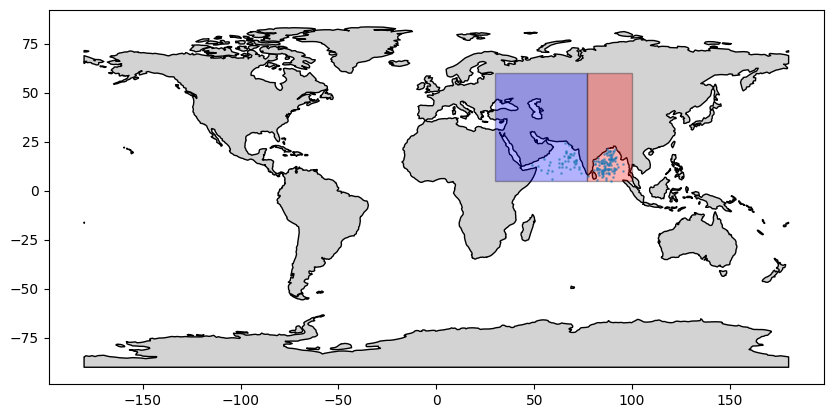

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(10, 5))

land_gdf.plot(ax=ax, color="lightgray", edgecolor="black")

ax.plot(genesis_ni["longitude"], genesis_ni["latitude"], "o", markersize=1, alpha=0.5)


rect = Rectangle(
    (CFG.lon_min, CFG.lat_min),
    width=77 - CFG.lon_min,
    height=CFG.lat_max - CFG.lat_min,
    facecolor="blue",
    alpha=0.3,
    edgecolor="black",
    linewidth=1,
)

ax.add_patch(rect)


rect = Rectangle(
    (77, CFG.lat_min),
    width=CFG.lon_max - 77,
    height=CFG.lat_max - CFG.lat_min,
    facecolor="red",
    alpha=0.3,
    edgecolor="black",
    linewidth=1,
)

ax.add_patch(rect)


plt.show()

### Load npy files

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr


path_files = Path(
    "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2025_VF/SIENA-IH-STORM/env_yearly"
)

# Files we actually need for the first genesis model.
NAME_MAP = {
    "VMAX_PI": "pi",  # thermodynamic PI maximum wind [m/s]
    "VWS": "vws",  # 850-200 hPa shear [m/s]
    "RH600": "rh600",  # relative humidity
    "VORT850": "vort850",  # relative vorticity [s-1]
    "SST" : "sst",
    "MSLP" : "slp"
}

NAME_MODEL = {
    "VMAX_PI": "pi",  # thermodynamic PI maximum wind [m/s]
    "VWS": "vws",  # 850-200 hPa shear [m/s]
    "RH600": "rh600",  # relative humidity
    "ETA850": "eta850",  # absolute vorticity capped [s-1]
    "W500" : "w500", # vertical velocity at 500hPa
    "SST" : "sst",
    "MSLP" : "slp"
}

START_YEAR = 1980
END_YEAR = 2025

def parse_env_filename(path):
    """
    Parse:
        VWS_2000_6.npy
        VMAX_PI_2000_6.npy
        VORT850_2018_10.npy

    Returns:
        variable, year, month
    """
    name, year, month = path.stem.rsplit("_", 2)

    return name, int(year), int(month)

In [9]:
def load_environment_dataset(
    path_files,
    name_map,
    start_year=1980,
    end_year=2024,
):
    path_files = Path(path_files)

    # Your arrays are the global 0.25° fields used elsewhere in the repo:
    # 721 latitudes: 90 -> -90
    # 1440 longitudes: 0 -> 359.75
    lat = np.linspace(90.0, -90.0, 721)
    lon = np.arange(1440) * 0.25

    variables = {}

    for file_name, xr_name in name_map.items():
        records = []

        for file in path_files.glob(f"{file_name}_*.npy"):
            name, year, month = parse_env_filename(file)

            if name != file_name:
                continue

            if not (start_year <= year <= end_year):
                continue

            records.append((year, month, file))

        records.sort(key=lambda x: (x[0], x[1]))

        if not records:
            raise FileNotFoundError(f"No files found for {file_name}")

        arrays = []
        times = []

        for year, month, file in records:
            arr = np.load(file)

            if arr.shape != (721, 1440):
                raise ValueError(f"{file.name}: expected (721, 1440), got {arr.shape}")

            arrays.append(arr)

            times.append(pd.Timestamp(year=year, month=month, day=1))

        variables[xr_name] = xr.DataArray(
            np.stack(arrays, axis=0),
            dims=("valid_time", "latitude", "longitude"),
            coords={
                "valid_time": pd.DatetimeIndex(times),
                "latitude": lat,
                "longitude": lon,
            },
            name=xr_name,
        )

    return xr.Dataset(variables)

env_native = load_environment_dataset(
    path_files=path_files,
    name_map=NAME_MAP,
    start_year=START_YEAR,
    end_year=END_YEAR,
)

OMEGA = 7.2921e-5

f = 2 * OMEGA * np.sin(np.deg2rad(env_native.latitude))

eta = env_native["vort850"] + f

env_native["eta850"] = xr.where(
    eta > 0,
    eta,
    0.0,
).clip(max=5e-5)

# TEMP FIX ADD W500
vv = xr.open_dataset("/home/mbaldacchino/data/vertical_velocity.grib")
vv = vv.rename_vars({"w": "w500"})

env_native = env_native.merge(
    vv.swap_dims({"time": "valid_time"})
    .sel(valid_time=slice("1980-01-01", "2025-12-01"))
    .drop_vars(["number", "time", "step"])
)

del vv

env_native = env_native.drop_vars(["vort850"])
env_native = env_native.sel(latitude=slice(CFG.lat_max + 2, CFG.lat_min - 2), longitude=slice(CFG.lon_min + 2, CFG.lon_max - 2))

/home/mbaldacchino/miniconda/envs/cat/lib/python3.13/site-packages/cfgrib/xarray_plugin.py:131: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


In [10]:

# COMPUTE rSST

JJASON = [6, 7, 8, 9, 10, 11]
ASO = [8,9,10]

def area_weighted_mean(da):
    weights = np.cos(np.deg2rad(da.latitude))

    return da.weighted(weights).mean(["latitude", "longitude"])

def area_weighted_mean_quantile(
    da,
    quantile=0.7,
):
    """
    Area-weighted mean of values above an area-weighted quantile.

    For SSTW30:
        quantile=0.7
    returns approximately the area-weighted mean SST of the
    warmest 30% of the domain.

    Assumes:
    - regular lat/lon grid
    - land points are NaN
    """

    weights = np.cos(np.deg2rad(da.latitude))

    # Area-weighted quantile at each time step
    threshold = da.weighted(weights).quantile(
        quantile,
        dim=["latitude", "longitude"],
        skipna=True,
    )

    # Keep only cells warmer than the weighted threshold
    warm = da.where(da >= threshold)

    # Area-weighted mean of those warmest cells
    return warm.weighted(weights).mean(
        ["latitude", "longitude"],
        skipna=True,
    )

MDR_SST = area_weighted_mean(
    env_native.sst.sel(
        latitude=slice(
            MDR_REGION["lat_max"],
            MDR_REGION["lat_min"],
        ),
        longitude=slice(
            MDR_REGION["lon_min"],
            MDR_REGION["lon_max"],
        ),
    )
)

TROPICS_SST = area_weighted_mean(
    env_native.sst.sel(
        latitude=slice(
            TROPICS_REGION["lat_max"],
            TROPICS_REGION["lat_min"],
        ),
        longitude=slice(
            TROPICS_REGION["lon_min"],
            TROPICS_REGION["lon_max"],
        ),
    )
)

SST_W30 = area_weighted_mean_quantile(
    env_native.sst.sel(
            latitude=slice(
                TROPICS_REGION["lat_max"],
                TROPICS_REGION["lat_min"],
            ),
            longitude=slice(
                TROPICS_REGION["lon_min"],
                TROPICS_REGION["lon_max"],
            ),
        ),
    quantile=0.70,
)

ds_rsst = xr.Dataset(
    {
        "mdr_sst": MDR_SST,
        "tropics_sst": TROPICS_SST,
        "rsst": MDR_SST - TROPICS_SST,
        "rsst_bis" : MDR_SST - SST_W30
    }
)

ds_jjason = ds_rsst.sel(valid_time=ds_rsst.valid_time.dt.month.isin(JJASON))
weights = ds_jjason.valid_time.dt.days_in_month
yearly = (ds_jjason * weights).groupby("valid_time.year").sum(
    "valid_time"
) / weights.groupby("valid_time.year").sum("valid_time")


ds_aso = ds_rsst.sel(valid_time=ds_rsst.valid_time.dt.month.isin(ASO))
weights = ds_aso.valid_time.dt.days_in_month
yearly_aso = (ds_aso * weights).groupby("valid_time.year").sum(
    "valid_time"
) / weights.groupby("valid_time.year").sum("valid_time")

yearly_df = yearly.to_dataframe().reset_index()
yearly_aso = yearly_aso.to_dataframe().reset_index()


env_native = env_native.drop_vars("sst")


## 2. Grid definition and exact spherical cell areas

A 1° latitude-longitude cell does not have the same area at 10°N and 50°N.
The exposure therefore uses spherical rectangle area rather than a constant cell area.

In [10]:
EARTH_RADIUS_KM = 6371.0088


def spherical_1deg_area_km2(lat_center):
    """Exact spherical area of a 1° x 1° lat/lon cell centered at lat_center."""
    lat_lo = np.deg2rad(np.asarray(lat_center) - 0.5)
    lat_hi = np.deg2rad(np.asarray(lat_center) + 0.5)
    dlon = np.deg2rad(1.0)
    return EARTH_RADIUS_KM**2 * dlon * (np.sin(lat_hi) - np.sin(lat_lo))


def build_existing_storm_exposure(
    basin: str,
    repo_root: Path,
) -> xr.Dataset:
    lat0, lat1, lon0, lon1 = gm.BOUNDARIES_BASINS(basin)
    rows = int(abs(lat1 - lat0))
    cols = int(abs(lon1 - lon0))

    # Existing authoritative 1° genesis-validity mask.
    ocean_valid = gm._genesis_ocean_mask_1deg(basin, (rows, cols))

    # Recover fractional ocean coverage from the exact same 0.1° mask.
    mask_path = os.path.join(repo_root, f"Land_ocean_masks/Land_ocean_mask_{basin}.txt")
    land10 = np.loadtxt(mask_path)

    # Same endpoint handling as _genesis_ocean_mask_1deg.
    land10 = land10[: rows * 10, : cols * 10]
    land_fraction = land10.reshape(rows, 10, cols, 10).mean(axis=(1, 3))
    ocean_fraction_raw = 1.0 - land_fraction

    # Preserve the exact existing genesis admissibility rule, including NA/EP split.
    eligible_fraction = np.where(ocean_valid, ocean_fraction_raw, 0.0)

    LAT2D, LON2D = gm.basin_cell_centers(basin, rows, cols)
    lat = LAT2D[:, 0]
    lon = LON2D[0, :]

    area_lat = spherical_1deg_area_km2(lat)
    cell_area = np.broadcast_to(area_lat[:, None], (rows, cols)).copy()
    eligible_area = cell_area * eligible_fraction

    return xr.Dataset(
        {
            "ocean_valid": (("latitude", "longitude"), ocean_valid),
            "raw_ocean_fraction": (("latitude", "longitude"), ocean_fraction_raw),
            "eligible_fraction": (("latitude", "longitude"), eligible_fraction),
            "cell_area_km2": (("latitude", "longitude"), cell_area),
            "eligible_area_km2": (("latitude", "longitude"), eligible_area),
        },
        coords={"latitude": lat, "longitude": lon},
    )


coarse_exposure = build_existing_storm_exposure(CFG.basin, REPO_ROOT)
coarse_exposure


<xarray.Dataset> Size: 128kB
Dimensions:             (latitude: 55, longitude: 70)
Coordinates:
  * latitude            (latitude) float64 440B 59.5 58.5 57.5 ... 7.5 6.5 5.5
  * longitude           (longitude) float64 560B 30.5 31.5 32.5 ... 98.5 99.5
Data variables:
    ocean_valid         (latitude, longitude) bool 4kB False False ... True True
    raw_ocean_fraction  (latitude, longitude) float64 31kB 0.05 0.0 ... 1.0 1.0
    eligible_fraction   (latitude, longitude) float64 31kB 0.0 0.0 ... 1.0 1.0
    cell_area_km2       (latitude, longitude) float64 31kB 6.275e+03 ... 1.23...
    eligible_area_km2   (latitude, longitude) float64 31kB 0.0 0.0 ... 1.231e+04

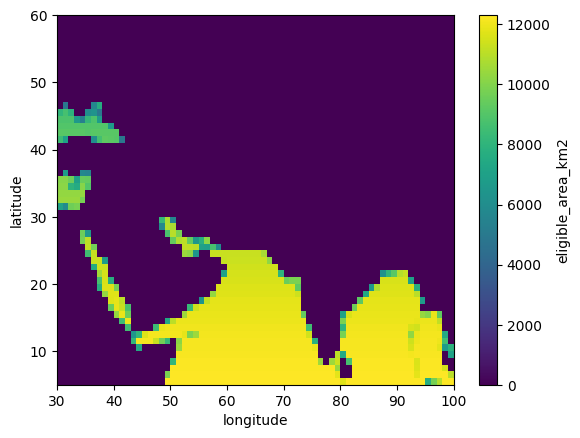

In [11]:
coarse_exposure.eligible_area_km2.plot()

## 4. Put environmental fields on the exact existing STORM 1° grid

Keep the project's 0–360° longitude convention.

The target coordinates come directly from `gm.basin_cell_centers()`, so the
environmental arrays, observed genesis counts, existing masks, and simulated
genesis probabilities all use the same row/column convention.

In [12]:
# FEATURES = ["pi", "rh600", "vws", "abs_vort850"]


def normalize_lon_360(ds: xr.Dataset, lon_name: str = "longitude") -> xr.Dataset:
    lon_new = ds[lon_name] % 360
    return ds.assign_coords({lon_name: lon_new}).sortby(lon_name)


def standardize_month_time(ds: xr.Dataset) -> xr.Dataset:
    t = pd.DatetimeIndex(ds.valid_time.values).to_period("M").to_timestamp()
    return ds.assign_coords(valid_time=t)

from time import time
def to_existing_storm_grid(ds: xr.Dataset, cfg: GenesisConfig) -> xr.Dataset:
    a = time()
    ds = normalize_lon_360(ds)
    print(time() - a)
    ds = standardize_month_time(ds)
    print(time() - a)
    ds = ds.sel(valid_time=ds.valid_time.dt.month.isin(ACTIVE_MONTHS[cfg.basin]))

    # xarray interpolation is safest with monotonic source coordinates.
    ds = ds.sortby("latitude").sortby("longitude")
    print(time() - a ) 
    # Target latitude is intentionally north->south to match genesis_matrix.py.
    out = ds.interp(latitude=LAT, longitude=LON)
    print(time() - a)
    return out


# Example if the fields are already suitable for direct interpolation:
env_1deg = to_existing_storm_grid(env_native, CFG)[
    list(NAME_MODEL.values())
]#[VARS_NAME]
#
# If your 0.25° preprocessing already has a preferred area/ocean-weighted
# 0.25° -> 1° aggregation, use that instead, but end on exactly LAT/LON above.


7.784722805023193
7.791759014129639
13.878075122833252
31.801549196243286


In [13]:
del(env_native)

### Recommended 0.25° → 1° aggregation

If your ERA5 fields are on a 0.25° grid aligned with the 1° cells, prefer an ocean-weighted block mean rather than interpolation. The exact implementation should reuse the land/basin mask already produced in your preprocessing pipeline.

Conceptually, for variable \(X\):

\[
X_{1^\circ}
=

rac{\sum_{j\in cell} X_j\,A_j\,I_{ocean,j}}
{\sum_{j\in cell} A_j\,I_{ocean,j}}.
\]

Do this consistently for ERA5 and any forecast fields that need regridding.

## 5. Historical genesis events

`genesis` should already contain exactly one row per storm under the definition you want the synthetic model to reproduce.

Recommended for compatibility with a STORM-like simulator:

- keep tropical/subtropical nature according to a fixed documented rule;
- identify the first fix at which the storm reaches the simulator's minimum wind threshold;
- use a single wind convention consistently;
- assign that time/location as the genesis event.

Do **not** fit a model to disturbance genesis if your simulator starts at tropical-storm genesis.

In [14]:
def normalize_lon_values(lon_values):
    """Use the same 0..360 convention as the STORM basin definitions."""
    return np.asarray(lon_values, dtype=float) % 360


def prepare_genesis_events(genesis: pd.DataFrame, cfg: GenesisConfig) -> pd.DataFrame:
    lat0, lat1, lon0, lon1 = gm.BOUNDARIES_BASINS(cfg.basin)

    g = genesis.copy()
    g["time"] = pd.to_datetime(g["time"])
    g["time_month"] = g["time"].dt.to_period("M").dt.to_timestamp()
    g["year"] = g["time"].dt.year
    g["month"] = g["time"].dt.month
    g["longitude"] = normalize_lon_values(g["longitude"])

    g = g[
        g["month"].isin(ACTIVE_MONTHS[cfg.basin])
        & g["latitude"].ge(lat0)
        & g["latitude"].lt(lat1)
        & g["longitude"].ge(lon0)
        & g["longitude"].lt(lon1)
    ].copy()

    return g


genesis = prepare_genesis_events(genesis_ni, CFG)

## 6. Assign observed genesis events to the existing 1° STORM cells

Rows are north-to-south and columns west-to-east, exactly as in
`basin_cell_centers()` and `_genesis_ocean_mask_1deg()`.

In [15]:
def assign_cells(df: pd.DataFrame, basin: str) -> pd.DataFrame:
    lat0, lat1, lon0, lon1 = gm.BOUNDARIES_BASINS(basin)
    rows = int(abs(lat1 - lat0))
    cols = int(abs(lon1 - lon0))

    out = df.copy()

    # Row 0 is [lat1-1, lat1), centered at lat1-0.5.
    ilat = np.floor(lat1 - out["latitude"].to_numpy()).astype(int)
    ilon = np.floor(out["longitude"].to_numpy() - lon0).astype(int)

    valid = (ilat >= 0) & (ilat < rows) & (ilon >= 0) & (ilon < cols)

    out = out.loc[valid].copy()
    out["ilat"] = ilat[valid]
    out["ilon"] = ilon[valid]
    out["cell_lat"] = LAT[out["ilat"].to_numpy()]
    out["cell_lon"] = LON[out["ilon"].to_numpy()]

    return out


genesis = assign_cells(genesis, CFG.basin)


### Bucket regions

In [16]:
def assign_genesis_region(lat, lon):
    """
    lon in 0..360 convention.
    """

    # Arabian Sea
    if 45 <= lon < 77 and 5 <= lat < 28:
        return "arabian_sea"

    # Everything farther north in the Atlantic
    return "bay_of_bengal"


genesis["region"] = [
    assign_genesis_region(lat, lon)
    for lat, lon in zip(
        genesis["latitude"],
        genesis["longitude"],
    )
]

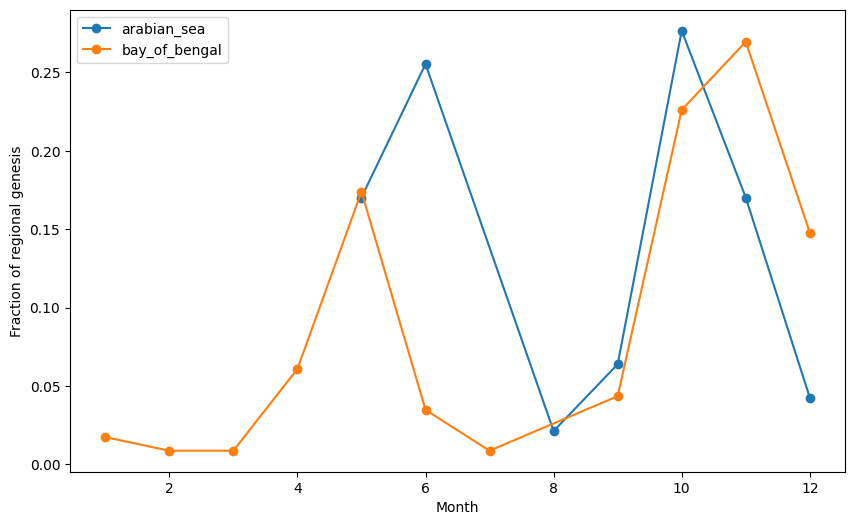

In [17]:
regional_month = (
    genesis.groupby(["region", "month"]).size().rename("count").reset_index()
)

regional_month["fraction"] = regional_month["count"] / regional_month.groupby("region")[
    "count"
].transform("sum")

fig, ax = plt.subplots(figsize=(10, 6))

for region, d in regional_month.groupby("region"):
    ax.plot(
        d["month"],
        d["fraction"],
        marker="o",
        label=region,
    )

ax.set_xlabel("Month")
ax.set_ylabel("Fraction of regional genesis")
ax.legend()

plt.show()

## 7. Build the cell-month modelling table

Every eligible 1° cell and every historical active-season month is one row.

The response is:

`genesis_count`

Most rows will be zero. That is expected and is **not** by itself evidence of zero inflation.

Exposure is:

\[
E_{iym}
=

rac{A^{eligible}_i}{100000\ km^2}
	imes

rac{days(m)}{30.44}.
\]

The scale constants only make the intercept readable.

In [48]:
def build_model_table(
    env_1deg: xr.Dataset,
    coarse_exposure: xr.Dataset,
    genesis_cells: pd.DataFrame,
    cfg: GenesisConfig,
) -> pd.DataFrame:
    missing = [v for v in list(NAME_MODEL.values()) if v not in env_1deg]
    if missing:
        raise KeyError(f"Missing environmental variables: {missing}")

    env_df = env_1deg[list(NAME_MODEL.values())].to_dataframe().reset_index()
    env_df["time"] = pd.to_datetime(env_df["valid_time"])
    env_df["year"] = env_df["time"].dt.year
    env_df["month"] = env_df["time"].dt.month

    exposure_df = (
        coarse_exposure[["ocean_valid", "eligible_area_km2", "eligible_fraction"]]
        .to_dataframe()
        .reset_index()
    )


    df = env_df.merge(exposure_df, on=["latitude", "longitude"], how="left")

    counts = (
        genesis_cells.groupby(["time_month", "cell_lat", "cell_lon"])
        .size()
        .rename("genesis_count")
        .reset_index()
        .rename(
            columns={
                "time_month": "time",
                "cell_lat": "latitude",
                "cell_lon": "longitude",
            }
        )
    )

    df = df.merge(counts, on=["time", "latitude", "longitude"], how="left")
    df["genesis_count"] = df["genesis_count"].fillna(0).astype(int)

    days = df["time"].dt.days_in_month.astype(float)
    df["exposure"] = (df["eligible_area_km2"] / cfg.area_unit_km2) * (
        days / cfg.reference_month_days
    )

    valid = (
        df["ocean_valid"].fillna(False)
        & (df["exposure"] > 0)
        & np.isfinite(df[list(NAME_MODEL.values())]).all(axis=1)
    )

    df = df.loc[valid].copy()
    df["log_exposure"] = np.log(df["exposure"])

    return df


model_df = build_model_table(env_1deg, coarse_exposure, genesis, CFG)
model_df.head()


,valid_time,latitude,longitude,pi,vws,rh600,eta850,w500,sst,slp,isobaricInhPa,time,year,month,ocean_valid,eligible_area_km2,eligible_fraction,genesis_count,exposure,log_exposure
916,1980-01-01,46.5,36.5,19.744682,12.578026,59.786011,0.00005,-0.022454,276.292969,1020.503723,500.0,1980-01-01,1980,1,True,5702.333839,0.67,0,0.058078,-2.845962
917,1980-01-01,46.5,37.5,19.744682,12.606691,59.450073,0.00005,-0.013055,276.698242,1020.711243,500.0,1980-01-01,1980,1,True,7659.851426,0.90,0,0.078016,-2.550845
985,1980-01-01,45.5,35.5,20.510181,12.597030,58.205933,0.00005,-0.041009,277.326172,1019.808716,500.0,1980-01-01,1980,1,True,5979.660454,0.69,0,0.060903,-2.798474
987,1980-01-01,45.5,37.5,20.055384,13.238761,59.106323,0.00005,-0.016900,277.275391,1020.086243,500.0,1980-01-01,1980,1,True,4939.719505,0.57,0,0.050311,-2.989529
1052,1980-01-01,44.5,32.5,20.543383,12.207848,58.123901,0.00005,-0.006646,281.839844,1018.906250,500.0,1980-01-01,1980,1,True,8818.763312,1.00,0,0.089819,-2.409956


## 8. Basic data diagnostics

Before fitting:

- verify observed annual/monthly counts;
- inspect environmental ranges at genesis vs all eligible ocean cells;
- inspect predictor correlation;
- check that no one variable contains unit mistakes.

In [49]:
def summarize_training_data(df: pd.DataFrame):
    print(f"Rows: {len(df):,}")
    print(f"Observed genesis events: {df.genesis_count.sum():,}")
    print()
    print("Events by month:")
    print(df.groupby("month")["genesis_count"].sum())
    print()
    print("Feature summary:")
    print(df[list(NAME_MODEL.values())].describe().T)
    print()
    print("Feature correlation:")
    print(df[list(NAME_MODEL.values())].corr())

summarize_training_data(model_df)

Rows: 418,416
Observed genesis events: 160

Events by month:
month
1      2
2      1
3      1
4      7
5     28
6     16
7      1
8      0
9      8
10    38
11    39
12    19
Name: genesis_count, dtype: int64

Feature summary:
           count         mean        std         min          25%  \
pi      418416.0    59.121525  13.648092    0.000000    55.277702   
vws     418416.0    19.080870  11.394738    0.019369     9.432581   
rh600   418416.0    38.940550  21.212905    2.194454    20.138092   
eta850  418416.0     0.000033   0.000014    0.000000     0.000024   
w500    418416.0     0.000280   0.041797   -0.476154    -0.017082   
sst     418416.0   300.625476   3.429234  272.528320   300.079102   
slp     418416.0  1010.109351   3.749553  994.282471  1008.284973   

                50%          75%          max  
pi        62.554863    67.873508    89.101372  
vws       16.921900    27.805917    71.118843  
rh600     37.827337    56.034479    92.645676  
eta850     0.000034     0.00

## 9. Temporal split: never split random grid rows

A random train/test split would leak the same years and monthly environments into both samples.

The first validation should hold out entire years.

In [ ]:
def split_by_year(df: pd.DataFrame, first_test_year: int):
    train = df[df["year"] < first_test_year].copy()
    test = df[df["year"] >= first_test_year].copy()
    return train, test

train, test = split_by_year(model_df, CFG.first_test_year)


# 1. Restrict to fixed NI physical domain
domain = train["latitude"].between(5, 30) & train["longitude"].between(45, 100)
train = train.loc[domain].copy()

domain = test["latitude"].between(5, 30) & test["longitude"].between(45, 100)
test = test.loc[domain].copy()


FULL_OCEAN_THRESHOLD = 0.999  # safer than == 1.0


train = train[train["eligible_fraction"] >= FULL_OCEAN_THRESHOLD].copy()

test = test[test["eligible_fraction"] >= FULL_OCEAN_THRESHOLD].copy()

## 10. Standardize environmental predictors using training data only

This is mainly numerical conditioning and makes coefficient magnitudes easier to compare.

In [54]:
def fit_standardizer(train: pd.DataFrame, features: list[str]):
    params = {}
    for col in features:
        mu = train[col].mean()
        sd = train[col].std()
        if not np.isfinite(sd) or sd == 0:
            raise ValueError(f"Invalid standard deviation for {col}: {sd}")
        params[col] = (mu, sd)
    return params

def apply_standardizer(df: pd.DataFrame, params):
    out = df.copy()
    for col, (mu, sd) in params.items():
        out[f"z_{col}"] = (out[col] - mu) / sd
    return out

scaler = fit_standardizer(train, list(NAME_MODEL.values()))
train = apply_standardizer(train, scaler)
test = apply_standardizer(test, scaler)

## 11. Fit two models

### Baseline M0
Seasonality only.

### Environmental M1
Seasonality + PI + RH + VWS + absolute vorticity.

For V1, month is categorical. This is transparent and handles unusual basin seasonal cycles without forcing a sinusoidal shape.

Later we can replace selected linear terms by physically motivated saturating functions or GAM splines.

In [22]:
list(NAME_MODEL.values())

['pi', 'vws', 'rh600', 'eta850', 'w500']

In [55]:
def fit_poisson_models(train: pd.DataFrame):
    baseline_formula = "genesis_count ~ C(month)"

    env_formula2 = (
        "genesis_count ~ " # C(month)"
        " + z_pi"
        " + z_vws"
        " + z_rh600"
        " + z_eta850"
        " + z_w500"
    )

    env_formula = (
            "genesis_count ~ C(month)"
            " + z_pi"
            " + z_vws"
            " + z_rh600"
            " + z_eta850"
        )

    m0 = smf.glm(
        baseline_formula,
        data=train,
        family=sm.families.Poisson(),
        offset=train["log_exposure"],
    ).fit()

    m1 = smf.glm(
        env_formula,
        data=train,
        family=sm.families.Poisson(),
        offset=train["log_exposure"],
    ).fit()

    m2 = smf.glm(
            env_formula2,
            data=train,
            family=sm.families.Poisson(),
            offset=train["log_exposure"],
        ).fit()



    return m0, m1, m2

m0, m1, m2 = fit_poisson_models(train)
print(m1.summary())
print(m2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          genesis_count   No. Observations:               275616
Model:                            GLM   Df Residuals:                   275600
Model Family:                 Poisson   Df Model:                           15
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -810.50
Date:                Fri, 16 Oct 2026   Deviance:                       1387.0
Time:                        11:28:34   Pearson chi2:                 9.81e+04
No. Iterations:                    25   Pseudo R-squ. (CS):           0.001557
Covariance Type:            nonrobust                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -7.8079      0.740    -10.

## 12. First model sanity checks

The expected physical signs are useful diagnostics, not hard constraints:

- PI: generally positive;
- RH: generally positive;
- VWS: generally negative;
- absolute vorticity: generally positive, potentially saturating.

A wrong sign does not automatically imply a bug because predictors are correlated. It should trigger:

- unit checks;
- correlation checks;
- univariate response plots;
- blocked-validation comparisons.

Also inspect Poisson dispersion, but judge overdispersion primarily at the **basin-month/year** level rather than from the enormous number of tiny cell means.

In [23]:
def pearson_dispersion(result) -> float:
    return float(np.sum(result.resid_pearson**2) / result.df_resid)

print("M0 dispersion:", pearson_dispersion(m0))
print("M1 dispersion:", pearson_dispersion(m1))
print("M2 dispersion:", pearson_dispersion(m2))

M0 dispersion: 0.9148076244899442
M1 dispersion: 0.3566211790015461
M2 dispersion: 0.40457419456691507


## 13. Held-out predictions

`statsmodels` returns the expected number of genesis events in each cell-month because the exposure offset is supplied at prediction time.

Therefore:

\[
\hat\Lambda_{ym} = \sum_i \hat\mu_{iym}
\]

is automatically the predicted basin-month frequency.

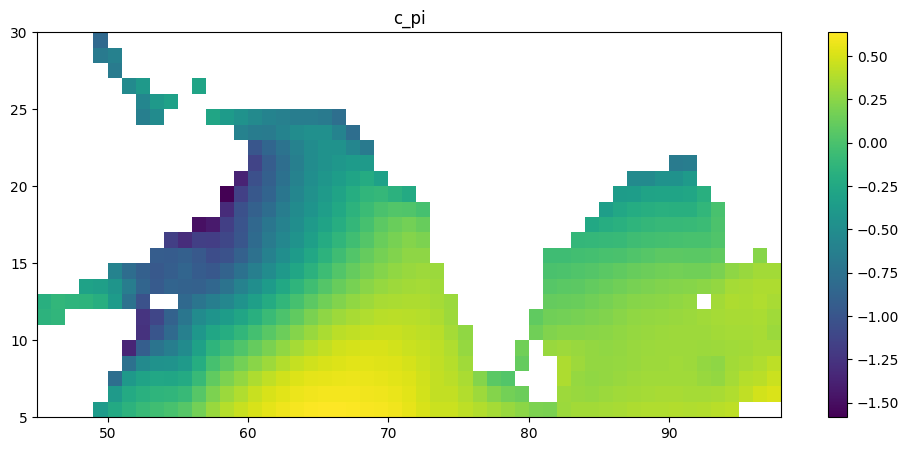

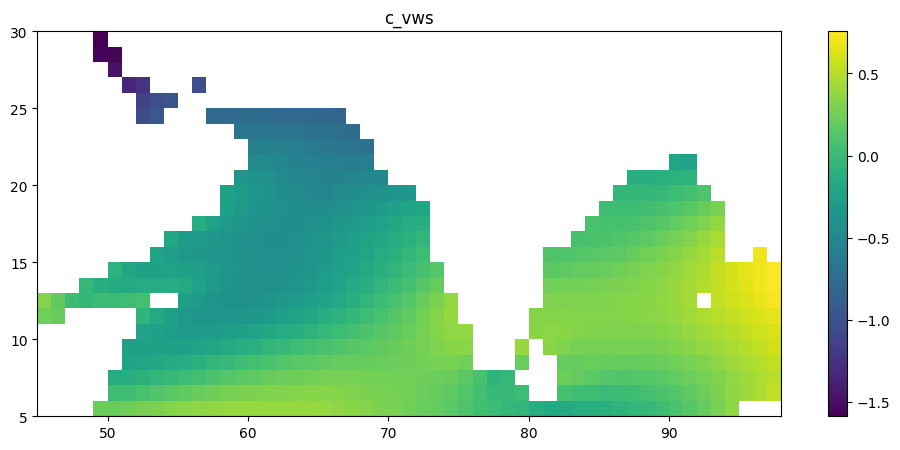

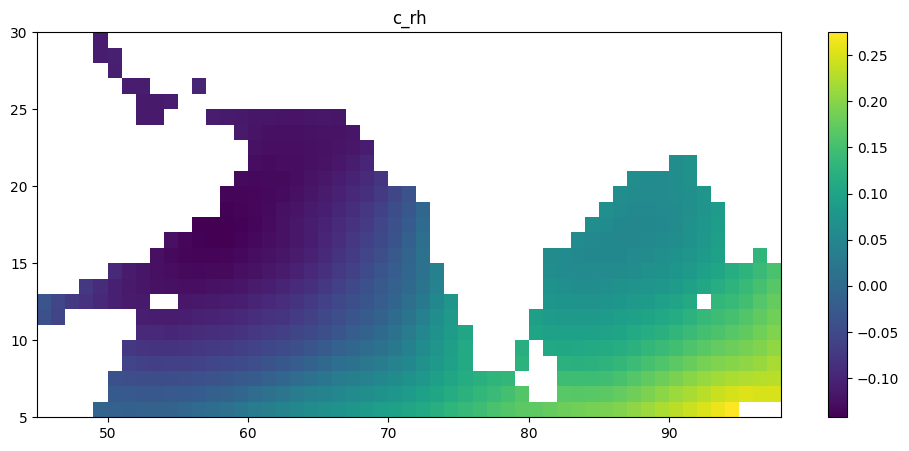

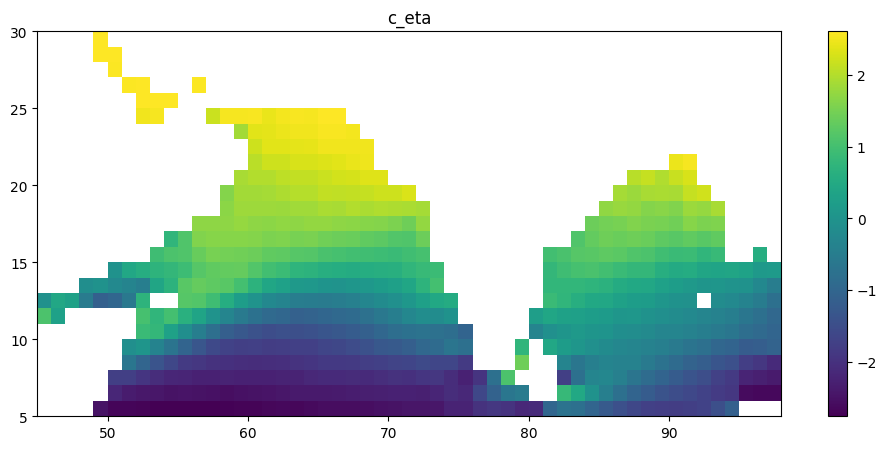

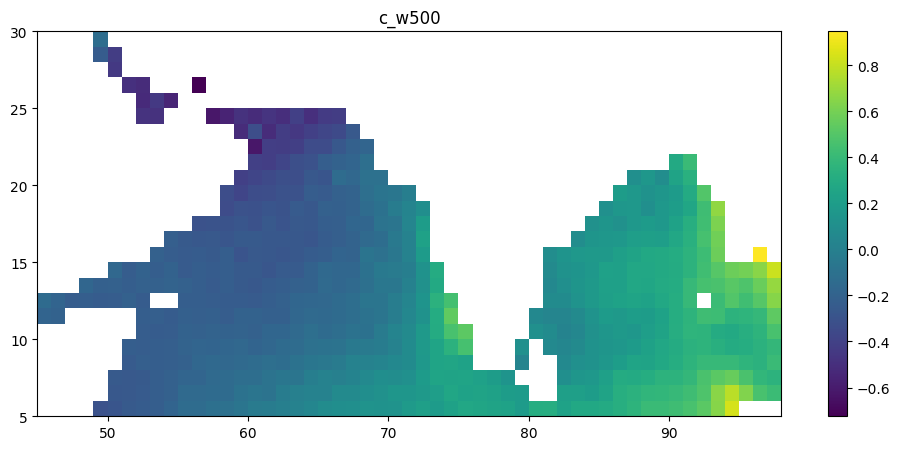

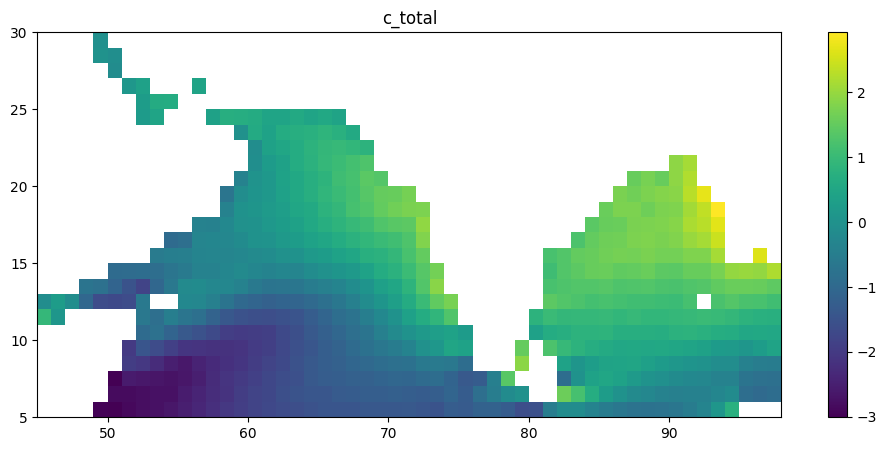

In [70]:
def add_predictions(df: pd.DataFrame, model, name: str) -> pd.DataFrame:
    out = df.copy()
    out[name] = model.predict(
        out,
        offset=out["log_exposure"],
    )
    return out

test = add_predictions(test, m0, "mu_m0")
test = add_predictions(test, m1, "mu_m1")
test = add_predictions(test, m2, "mu_m2")

params = m2.params

for var in ["z_pi", "z_vws", "z_rh600", "z_eta850", "z_w500"]:
    test[f"contrib_{var}"] = params[var] * test[var]

test["contrib_total"] = test[["contrib_z_pi", "contrib_z_vws", "contrib_z_rh600", "contrib_z_eta850", "contrib_z_w500"]].sum(axis=1)

diagnostic = (
    test.groupby(["latitude", "longitude"])
    .agg(
        expected=("mu_m2", "sum"),
        observed=("genesis_count", "sum"),
        z_pi=("z_pi", "mean"),
        z_vws=("z_vws", "mean"),
        z_rh600=("z_rh600", "mean"),
        z_eta850=("z_eta850", "mean"),
        z_w500=("z_w500", "mean"),
        c_pi=("contrib_z_pi", "mean"),
        c_vws=("contrib_z_vws", "mean"),
        c_rh=("contrib_z_rh600", "mean"),
        c_eta=("contrib_z_eta850", "mean"),
        c_w500=("contrib_z_w500", "mean"),
        c_total=("contrib_total", "mean"),
        )
    .reset_index()
)

diagnostic.sort_values("expected", ascending=False).head(30)

for col in ["c_pi", "c_vws", "c_rh", "c_eta", "c_w500","c_total"]:
    a = diagnostic.pivot(
        index="latitude",
        columns="longitude",
        values=col,
    )

    fig, ax = plt.subplots(figsize=(12, 5))
    im = ax.pcolormesh(
        a.columns,
        a.index,
        a.values,
        shading="auto",
    )
    ax.set_title(col)
    plt.colorbar(im, ax=ax)
    plt.show()



In [101]:
base = train_soft.copy()

base["mu"] = m_ni_season.predict(
    base,
    offset=base["log_exposure"],
)

vars_ = ["z_pi", "z_vws", "z_eta850", "z_w500"]

for var in vars_:
    cf = base.copy()
    cf[var] = 0.0

    base[f"mu_without_{var}"] = m_ni_season.predict(
        cf,
        offset=cf["log_exposure"],
    )


spatial = base.groupby(["latitude", "longitude"]).agg(
    mu=("mu", "sum"),
    mu_no_pi=("mu_without_z_pi", "sum"),
    mu_no_vws=("mu_without_z_vws", "sum"),
    mu_no_eta=("mu_without_z_eta850", "sum"),
    mu_no_w500=("mu_without_z_w500", "sum"),
)

for var in ["pi", "vws", "eta", "w500"]:
    spatial[f"effect_{var}"] = spatial["mu"] / spatial[f"mu_no_{var}"]


se = base[(base["longitude"] >= 90) & (base["latitude"] >= 17)]

(
    se.groupby("month").agg(
        observed=("genesis_count", "sum"),
        expected=("mu", "sum"),
        pi=("z_pi", "mean"),
        vws=("z_vws", "mean"),
        eta=("z_eta_clip", "mean"),
        w500=("z_w500", "mean"),
    )
)

,observed,expected,pi,vws,eta,w500
month,,,,,,
1,0,0.149381,-1.307531,0.726344,1.073644,0.833817
2,0,0.138356,-1.046855,0.699269,1.014959,0.819096
3,0,0.076180,0.099205,0.531051,0.744728,0.764194
4,0,0.140040,0.216892,-0.015005,0.580212,0.590308
5,0,2.744034,-0.130263,-1.166990,0.995929,-0.592100
6,1,4.722762,-0.460405,-0.115370,1.144344,-3.431224
7,1,0.422959,-0.615933,0.476034,1.135683,-3.315956
8,0,0.357768,-0.699168,0.300979,1.138315,-2.806596
9,0,0.478682,-0.194168,-0.417112,1.127878,-1.760418


In [103]:
se_bis = base[(base["longitude"] >= 80) & (base["longitude"] <= 90) & (base["latitude"] >= 10) & (base["latitude"] <= 20)]

(
    se_bis.groupby("month").agg(
        observed=("genesis_count", "sum"),
        expected=("mu", "sum"),
        pi=("z_pi", "mean"),
        vws=("z_vws", "mean"),
        eta=("z_eta850", "mean"),
        w500=("z_w500", "mean"),
    )
)


,observed,expected,pi,vws,eta,w500
month,,,,,,
1,0,0.429018,-0.036287,-0.045603,0.068832,0.611460
2,1,0.375951,0.186809,-0.094642,-0.055574,0.632220
3,1,0.206095,0.653960,-0.169481,-0.173686,0.609587
4,3,0.979705,0.444375,-0.585319,0.039360,0.400437
5,7,4.829630,-0.303601,-0.906463,0.638946,-0.083735
6,2,2.248491,-0.509140,0.585078,0.757831,-1.130528
7,0,0.261558,-0.487328,1.002195,0.635430,-1.225445
8,0,0.327793,-0.522287,0.932588,0.662797,-1.167772
9,2,0.543919,-0.170108,0.244157,0.767958,-0.998871


In [87]:
print(m_ni_season.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          genesis_count   No. Observations:               275616
Model:                            GLM   Df Residuals:                   275609
Model Family:                 Poisson   Df Model:                            6
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -803.53
Date:                Fri, 16 Oct 2026   Deviance:                       1373.1
Time:                        11:49:48   Pearson chi2:                 1.03e+05
No. Iterations:                    13   Pseudo R-squ. (CS):           0.001608
Covariance Type:            nonrobust                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2


def binned_genesis_rate(
    df,
    variable,
    n_bins=20,
    q=(0.01, 0.99),
):
    d = (
        df[
            [
                variable,
                "genesis_count",
                "exposure",
            ]
        ]
        .dropna()
        .copy()
    )

    # Remove only the most extreme tails for visualization.
    # Do not do this automatically in the fitted model.
    lo, hi = d[variable].quantile(q)
    d = d[d[variable].between(lo, hi)]

    d["bin"] = pd.qcut(
        d[variable],
        q=n_bins,
        duplicates="drop",
    )

    out = (
        d.groupby("bin", observed=True)
        .agg(
            x=(variable, "mean"),
            count=("genesis_count", "sum"),
            exposure=("exposure", "sum"),
            n=("genesis_count", "size"),
        )
        .reset_index(drop=True)
    )

    out["rate"] = out["count"] / out["exposure"]

    # Exact Poisson confidence interval for number of events
    alpha = 0.05

    out["rate_low"] = np.where(
        out["count"] > 0,
        0.5 * chi2.ppf(alpha / 2, 2 * out["count"]) / out["exposure"],
        0.0,
    )

    out["rate_high"] = (
        0.5
        * chi2.ppf(
            1 - alpha / 2,
            2 * (out["count"] + 1),
        )
        / out["exposure"]
    )

    return out

variables = [
    "pi",
    "rh600",
    "vws",
    "eta_clip",
    "w500"
]

for variable in variables:
    d = binned_genesis_rate(
        train_eta,
        variable,
        n_bins=20,
    )

    d_bis = binned_genesis_rate(
            test_eta,
            variable,
            n_bins=20,
        )

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(
        d["x"],
        np.log(d["rate"]),
        marker="o",
    )

    ax.plot(
            d_bis["x"],
            np.log(d_bis["rate"]),
            marker="x",
        )

    ax.fill_between(
        d["x"],
        np.log(d["rate_low"].replace(0, np.nan)),
        np.log(d["rate_high"]),
        alpha=0.2,
    )

    ax.set_xlabel(variable)
    ax.set_ylabel("log(genesis rate)")
    ax.set_title(f"Empirical genesis response to {variable}")

    plt.show()

NameError: name 'train_eta' is not defined

### Basin-month verification

The sum of independent Poisson variables is Poisson, so the aggregate predicted basin-month count is:

\[
N_{ym}\sim Pois(\Lambda_{ym}),
\qquad
\Lambda_{ym}=\sum_i\mu_{iym}.
\]

This gives a natural probabilistic score without any extra calibration layer.

In [29]:
def basin_month_scores(df: pd.DataFrame, mu_col: str) -> tuple[pd.DataFrame, dict]:
    agg = (
        df.groupby(["year", "month"], as_index=False)
        .agg(
            observed=("genesis_count", "sum"),
            lambda_pred=(mu_col, "sum"),
        )
    )

    agg["log_score"] = poisson.logpmf(
        agg["observed"],
        np.clip(agg["lambda_pred"], 1e-12, None),
    )

    metrics = {
        "mean_log_score": agg["log_score"].mean(),
        "bias": (agg["lambda_pred"] - agg["observed"]).mean(),
        "mae": np.abs(agg["lambda_pred"] - agg["observed"]).mean(),
        "rmse": np.sqrt(
            np.mean((agg["lambda_pred"] - agg["observed"]) ** 2)
        ),
    }
    return agg, metrics

agg0, score0 = basin_month_scores(test, "mu_m0")
agg1, score1 = basin_month_scores(test, "mu_m1")
agg2, score2 = basin_month_scores(test, "mu_m2")
print("M0:", score0)
print("M1:", score1)
print("M2: ", score2)

M0: {'mean_log_score': np.float64(-0.549256945370902), 'bias': np.float64(-0.05323664372008104), 'mae': np.float64(0.30231891183547693), 'rmse': np.float64(0.4593425901260511)}
M1: {'mean_log_score': np.float64(-0.5713539392451304), 'bias': np.float64(-0.02086580078912596), 'mae': np.float64(0.3197520307369339), 'rmse': np.float64(0.51697822904569)}
M2:  {'mean_log_score': np.float64(-0.559102224488227), 'bias': np.float64(-0.0206441304637427), 'mae': np.float64(0.30720136054439934), 'rmse': np.float64(0.515620971051237)}


### Spatial held-out log score

For the gridded point-process approximation, the cell-month Poisson log likelihood is also the natural spatial occurrence score.

Compare models only on exactly the same held-out rows.

In [75]:
def heldout_cell_loglik(df: pd.DataFrame, mu_col: str) -> float:
    y = df["genesis_count"].to_numpy()
    mu = np.clip(df[mu_col].to_numpy(), 1e-15, None)
    return float(poisson.logpmf(y, mu).sum())

print("M0 cell loglik:", heldout_cell_loglik(test, "mu_m0"))
print("M1 cell loglik:", heldout_cell_loglik(test, "mu_m1"))
print("M2 cell loglik:", heldout_cell_loglik(test, "mu_m2"))

M0 cell loglik: -321.3648117664391
M1 cell loglik: -279.9591796197083
M2 cell loglik: -283.6692465913276


### Threshold eta

In [83]:
thresholds = np.arange(2.5e-5, 5.1e-5, 0.2e-5)

results = []

for threshold in thresholds:
    train_tmp = train_soft.copy()
    test_tmp = test_soft.copy()

    train_tmp["eta_clip"] = np.minimum(
        train_tmp["eta850"],
        threshold,
    )

    test_tmp["eta_clip"] = np.minimum(
        test_tmp["eta850"],
        threshold,
    )

    mu = train_tmp["eta_clip"].mean()
    sd = train_tmp["eta_clip"].std()

    train_tmp["z_eta_clip"] = (train_tmp["eta_clip"] - mu) / sd

    test_tmp["z_eta_clip"] = (test_tmp["eta_clip"] - mu) / sd


    model = smf.glm(
        "genesis_count ~ C(ni_season) + C(region)  + z_vws + z_eta_clip + z_w500",
        data=train_tmp,
        family=sm.families.Poisson(),
        offset=train_tmp["log_exposure"],
    ).fit()

    test_tmp["mu"] = model.predict(
        test_tmp,
        offset=test_tmp["log_exposure"],
    )

    score = heldout_cell_loglik(
        test_tmp.rename(columns={"mu": "mu_test"}),
        "mu_test",
    )

    results.append((threshold, score))


In [84]:
results

[(np.float64(2.5e-05), -314.5503264812161),
 (np.float64(2.7000000000000002e-05), -317.58115621333525),
 (np.float64(2.9000000000000004e-05), -315.07825925949174),
 (np.float64(3.100000000000001e-05), -301.1760391904317),
 (np.float64(3.3e-05), -295.3401898064818),
 (np.float64(3.500000000000001e-05), -292.3856755282869),
 (np.float64(3.7000000000000005e-05), -290.8450590673703),
 (np.float64(3.900000000000001e-05), -289.0481910736516),
 (np.float64(4.100000000000001e-05), -287.6698184758287),
 (np.float64(4.3000000000000015e-05), -286.23808121131344),
 (np.float64(4.500000000000001e-05), -285.2510740998414),
 (np.float64(4.700000000000002e-05), -284.0159057238697),
 (np.float64(4.900000000000001e-05), -282.95243014025857)]

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import poisson
from patsy import bs


In [78]:
def predict_mu(model, df):
    return model.predict(
        df,
        offset=df["log_exposure"],
    )


def cell_log_score(df, mu):
    """
    Total held-out Poisson log-likelihood at cell-month level.
    Higher = better.
    """
    y = df["genesis_count"].to_numpy()
    mu = np.clip(np.asarray(mu), 1e-15, None)

    return poisson.logpmf(y, mu).sum()


def basin_month_score(df, mu):
    """
    Aggregate cell expectations to basin-month before scoring.
    This evaluates the frequency component more directly.
    """
    d = df[["year", "month", "genesis_count"]].copy()

    d["mu"] = mu

    agg = d.groupby(["year", "month"], as_index=False).agg(
        observed=("genesis_count", "sum"),
        expected=("mu", "sum"),
    )

    agg["log_score"] = poisson.logpmf(
        agg["observed"],
        np.clip(agg["expected"], 1e-15, None),
    )

    return {
        "monthly_log_score": agg["log_score"].sum(),
        "monthly_mean_log_score": agg["log_score"].mean(),
        "monthly_bias": (agg["expected"] - agg["observed"]).mean(),
        "monthly_rmse": np.sqrt(np.mean((agg["expected"] - agg["observed"]) ** 2)),
    }


def evaluate_model(name, model, test_df):
    mu = predict_mu(model, test_df)

    scores = basin_month_score(test_df, mu)

    return {
        "model": name,
        "cell_log_score": cell_log_score(
            test_df,
            mu,
        ),
        **scores,
    }


In [79]:
FORMULA_LINEAR = "genesis_count ~ C(month) + z_pi + z_rh600 + z_vws + z_eta850"

m_linear = smf.glm(
    formula=FORMULA_LINEAR,
    data=train,
    family=sm.families.Poisson(),
    offset=train["log_exposure"],
).fit()


In [80]:
results = [
    evaluate_model(
        "linear",
        m_linear,
        test,
    )
]

pd.DataFrame(results)


,model,cell_log_score,monthly_log_score,monthly_mean_log_score,monthly_bias,monthly_rmse
0,linear,-279.95918,-69.674057,-0.580617,-0.034416,0.530025


In [81]:
ETA_THRESHOLDS = np.arange(
    2.5e-5,
    5.01e-5,
    0.25e-5,
)

def prepare_clipped_eta(
    train,
    test,
    threshold,
):
    train_tmp = train.copy()
    test_tmp = test.copy()

    train_tmp["eta_clip"] = np.minimum(
        train_tmp["eta850"],
        threshold,
    )

    test_tmp["eta_clip"] = np.minimum(
        test_tmp["eta850"],
        threshold,
    )

    # Standardization fitted ONLY on training period
    mean_eta = train_tmp["eta_clip"].mean()
    std_eta = train_tmp["eta_clip"].std()

    train_tmp["z_eta_clip"] = (train_tmp["eta_clip"] - mean_eta) / std_eta

    test_tmp["z_eta_clip"] = (test_tmp["eta_clip"] - mean_eta) / std_eta

    return train_tmp, test_tmp

### Spatial Approach with PATSY CR/TE

In [94]:
train_eta, test_eta = prepare_clipped_eta(
        train,
        test,
        4.0e-5,
    )



# 2. Apply the ocean / eligible-area mask
#train_ni = train_ni[train_ni["eligible_area_km2"] > 0].copy()

# 3. Recompute predictor standardisation ON THIS training domain
# 4. Fit the model

FORMULA_BASE = "genesis_count ~ C(month) + z_pi + z_rh600 + z_vws + z_eta_clip + z_w500"

m_base = smf.glm(
    FORMULA_BASE,
    data=train_eta,
    family=sm.families.Poisson(),
    offset=train_eta["log_exposure"],
).fit()


FORMULA_REGION_MONTH = (
    "genesis_count ~ C(region) * C(month)"
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
)


train_eta["region"] = [
    assign_genesis_region(lat, lon)
    for lat, lon in zip(
        train_eta["latitude"],
        train_eta["longitude"],
    )
]

test_eta["region"] = [
    assign_genesis_region(lat, lon)
    for lat, lon in zip(
        test_eta["latitude"],
        test_eta["longitude"],
    )
]

m_region_month = smf.glm(
    FORMULA_REGION_MONTH,
    data=train_eta,
    family=sm.families.Poisson(),
    offset=train_eta["log_exposure"],
).fit()



REGIONS = [
    "arabian_sea",
    "bay_of_bengal"
]



In [95]:
region_grid = (
    train_eta[["latitude", "longitude", "region"]]
    .drop_duplicates(["latitude", "longitude"])
    .pivot(
        index="latitude",
        columns="longitude",
        values="region",
    )
)

import numpy as np
from scipy.ndimage import gaussian_filter

regions = sorted(train_eta["region"].unique())

hard_masks = {}

for region in regions:
    hard_masks[region] = (region_grid.values == region).astype(float)

In [99]:
soft_masks = {}

for region in regions:
    soft_masks[region] = gaussian_filter(
        hard_masks[region],
        sigma=3.0,
        mode="nearest",
    )

total = np.zeros_like(next(iter(soft_masks.values())))

for field in soft_masks.values():
    total += field

total = np.where(
    total > 0,
    total,
    np.nan,
)

for region in regions:
    soft_masks[region] = soft_masks[region] / total


weights_df = []

lat_values = region_grid.index.to_numpy()
lon_values = region_grid.columns.to_numpy()

for i, lat in enumerate(lat_values):
    for j, lon in enumerate(lon_values):
        row = {
            "latitude": lat,
            "longitude": lon,
        }

        for region in regions:
            row[f"w_{region}"] = soft_masks[region][i, j]

        weights_df.append(row)

weights_df = pd.DataFrame(weights_df)

train_soft = train_eta.merge(
        weights_df,
        on=["latitude", "longitude"],
        how="left",
    )

test_soft = test_eta.merge(
    weights_df,
    on=["latitude", "longitude"],
    how="left",
)
REFERENCE_REGION = "bay_of_bengal"

varying_regions = [r for r in regions if r != REFERENCE_REGION]
region_terms = " + ".join(f"w_{r}" for r in varying_regions)

interaction_terms = " + ".join(f"w_{r}:C(month)" for r in varying_regions)

FORMULA_SOFT_REGION_MONTH = (
    "genesis_count ~  C(month)"
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta850"
    " + z_w500"
    f" + {region_terms}"
    #f" + {interaction_terms}"
)
m_soft_region_month = smf.glm(
    formula=FORMULA_SOFT_REGION_MONTH,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()

formula_no_month = (
    "genesis_count ~ "
    "z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta850"
    " + z_w500"
    " + w_arabian_sea"
)

m_no_month = smf.glm(
    formula_no_month,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()


FORMULA_NI = (
    "genesis_count ~ C(month) * C(region) + z_pi + z_rh600 + z_vws + z_eta850 + z_w500"
)

m_ni = smf.glm(
    formula=FORMULA_NI,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()

print(m_ni.summary())


def ni_season(month):
    if month in [3, 4, 5, 6]:
        return "pre_monsoon"
    elif month in [7, 8, 9]:
        return "monsoon"
    else:
        return "post_monsoon"


train_soft["ni_season"] = train_soft["month"].map(ni_season)

test_soft["ni_season"] = test_soft["month"].map(ni_season)

train_soft, test_soft = prepare_clipped_eta(
    train_soft,
    test_soft,
    5.0e-5,
)


FORMULA_NI_SEASON = (
    "genesis_count ~ C(ni_season) + C(region) + z_eta_clip +  z_vws + z_w500 " 
)

m_ni_season = smf.glm(
    formula=FORMULA_NI_SEASON,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()

print("5e-5 threshold")
print(m_ni_season.summary())


train_soft, test_soft = prepare_clipped_eta(
    train_soft,
    test_soft,
    4.0e-5,
)


FORMULA_NI_SEASON = (
    "genesis_count ~ C(ni_season) + C(region) + z_eta_clip +  z_vws + z_w500 "
)

m_ni_season = smf.glm(
    formula=FORMULA_NI_SEASON,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()

print("4e-5 threshold")
print(m_ni_season.summary())


train_soft, test_soft = prepare_clipped_eta(
    train_soft,
    test_soft,
    4.5e-5,
)


FORMULA_NI_SEASON = (
    "genesis_count ~ C(ni_season) + C(region) + z_eta_clip +  z_vws + z_w500 "
)

m_ni_season = smf.glm(
    formula=FORMULA_NI_SEASON,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()

print("4.5e-5 threshold")
print(m_ni_season.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:          genesis_count   No. Observations:               275616
Model:                            GLM   Df Residuals:                   275587
Model Family:                 Poisson   Df Model:                           28
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -783.64
Date:                Fri, 16 Oct 2026   Deviance:                       1333.3
Time:                        12:08:37   Pearson chi2:                 8.08e+04
No. Iterations:                    26   Pseudo R-squ. (CS):           0.001752
Covariance Type:            nonrobust                                         
                                                coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

In [40]:
def monthly_region_calibration(df, model, name):
    x = df.copy()

    x["mu"] = model.predict(
        x,
        offset=x["log_exposure"],
    )

    out = x.groupby(
        ["region", "month"],
        as_index=False,
    ).agg(
        observed=("genesis_count", "sum"),
        expected=("mu", "sum"),
    )

    out["obs_exp"] = out["observed"] / out["expected"]

    out["model"] = name

    return out


In [89]:
calib_base = monthly_region_calibration(
    train_soft,
    m_no_month,
    "Environment",
)

calib_ni = monthly_region_calibration(
    train_soft,
    m_ni,
    "Month × region",
)

calib_ni_season = monthly_region_calibration(
    train_soft,
    m_ni_season,
    "Season × region",
)


calib_compare = pd.concat(
    [calib_base, calib_ni, calib_ni_season],
    ignore_index=True,
)


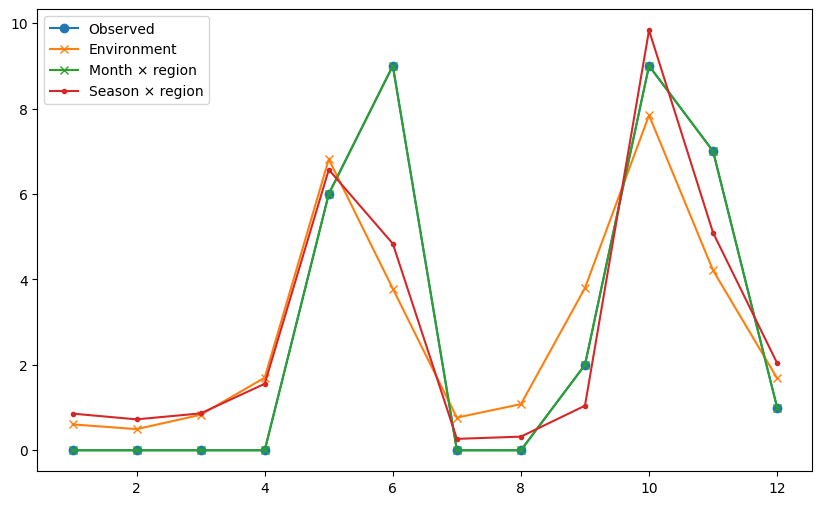

In [90]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    calib_compare.loc[(calib_compare["model"] == "Environment") & (calib_compare["region"] == "arabian_sea"), "month"],
    calib_compare.loc[(calib_compare["model"] == "Environment") & (calib_compare["region"] == "arabian_sea"), "observed"],
    marker="o",
    label="Observed",
)

ax.plot(
    calib_compare.loc[
        (calib_compare["model"] == "Environment")
        & (calib_compare["region"] == "arabian_sea"),
        "month",
    ],
    calib_compare.loc[
        (calib_compare["model"] == "Environment")
        & (calib_compare["region"] == "arabian_sea"),
        "expected",
    ],
    marker="x",
    label="Environment",
)
ax.plot(
    calib_compare.loc[
        (calib_compare["model"] == "Month × region")
        & (calib_compare["region"] == "arabian_sea"),
        "month",
    ],
    calib_compare.loc[
        (calib_compare["model"] == "Month × region")
        & (calib_compare["region"] == "arabian_sea"),
        "expected",
    ],
    marker="x",
    label="Month × region",
)

ax.plot(
    calib_compare.loc[
        (calib_compare["model"] == "Season × region")
        & (calib_compare["region"] == "arabian_sea"),
        "month",
    ],
    calib_compare.loc[
        (calib_compare["model"] == "Season × region")
        & (calib_compare["region"] == "arabian_sea"),
        "expected",
    ],
    marker=".",
    label="Season × region",
)
ax.legend()

In [90]:
historical = (
    pd.concat(
        [train_soft, test_soft],
        ignore_index=True,
    )
    .sort_values(["year", "month", "latitude", "longitude"])
    .reset_index(drop=True)
)
historical["mu_base"] = m_linear.predict(
    historical,
    offset=historical["log_exposure"],
)
historical_soft = historical #.merge(
#     weights_df,  # weights_df created with sigma=3
#     on=["latitude", "longitude"],
#     how="left",
# )
historical_soft["mu_smooth"] = m_soft_region_month.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)
historical_soft["mu_ni_season"] = m_ni_season.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)

historical_soft["mu_ni"] = m_ni.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)

In [91]:
annual_base = historical.groupby("year", as_index=False).agg(
    observed=("genesis_count", "sum"),
    expected_base=("mu_base", "sum"),
)
annual_smooth = historical_soft.groupby("year", as_index=False).agg(
    expected_smooth=("mu_smooth", "sum"),
)
annual = annual_base.merge(
    annual_smooth,
    on="year",
    how="left",
)
annual_ni_season = historical_soft.groupby("year", as_index=False).agg(
    expected_ni_season=("mu_ni_season", "sum"),
)
annual = annual.merge(
    annual_ni_season,
    on="year",
    how="left",
)

annual_ni = historical_soft.groupby("year", as_index=False).agg(
    expected_ni=("mu_ni", "sum"),
)
annual = annual.merge(
    annual_ni,
    on="year",
    how="left",
)

annual

,year,observed,expected_base,expected_smooth,expected_ni_season,expected_ni
0,1980,0,2.743244,2.870776,3.138508,2.895386
1,1981,0,3.343908,3.141562,2.648409,3.219844
2,1982,5,2.153013,2.236481,3.400456,2.042250
3,1983,2,4.069418,3.404494,2.830640,3.340787
4,1984,3,2.575724,2.922376,3.665158,2.896051
5,1985,7,3.159420,3.468433,3.089337,3.234480
6,1986,0,2.125200,2.064269,2.558730,2.041539
7,1987,5,3.959554,3.765316,3.468175,3.786244
8,1988,2,3.148251,3.750689,3.612839,3.751201
9,1989,0,2.615979,3.288762,3.615497,3.155426


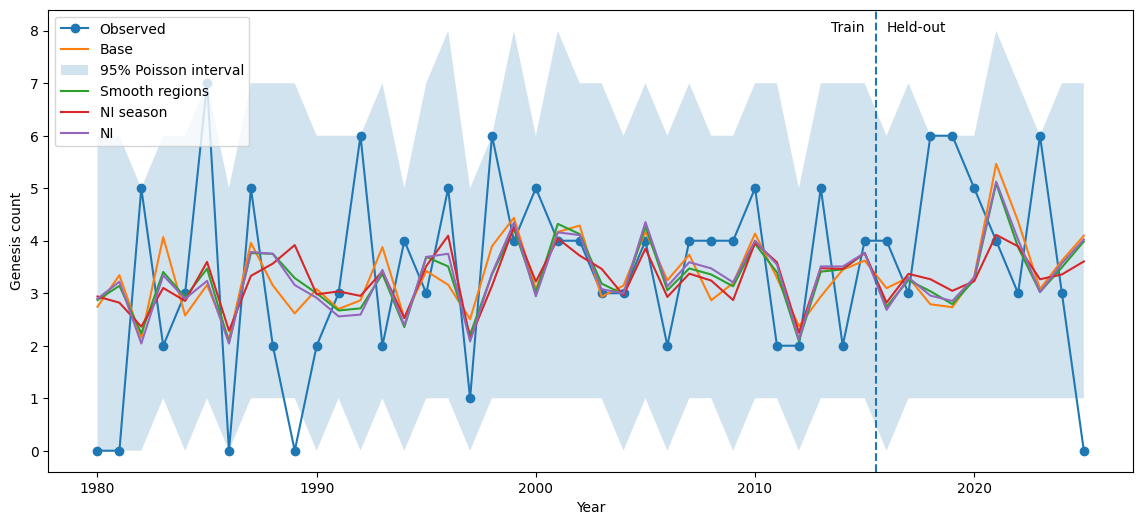

In [66]:
fig, ax = plt.subplots(figsize=(14, 6))
from scipy.stats import poisson

annual["base_low"] = poisson.ppf(
    0.025,
    annual["expected_base"],
)

annual["base_high"] = poisson.ppf(
    0.975,
    annual["expected_base"],
)

annual["smooth_low"] = poisson.ppf(
    0.05,
    annual["expected_smooth"],
)

annual["smooth_high"] = poisson.ppf(
    0.95,
    annual["expected_smooth"],
)

annual["ni_season_low"] = poisson.ppf(
    0.05,
    annual["expected_ni_season"],
)

annual["ni_season_high"] = poisson.ppf(
    0.95,
    annual["expected_ni_season"],
)


ax.plot(
    annual["year"],
    annual["observed"],
    marker="o",
    label="Observed",
)

ax.plot(
    annual["year"],
    annual["expected_base"],
    label="Base",
)

ax.fill_between(
    annual["year"],
    annual["ni_season_low"],
    annual["ni_season_high"],
    alpha=0.2,
    label="95% Poisson interval",
)



ax.plot(
    annual["year"],
    annual["expected_smooth"],
    label="Smooth regions",
)


ax.plot(
    annual["year"],
    annual["expected_ni_season"],
    label="NI season",
)

ax.plot(
    annual["year"],
    annual["expected_ni"],
    label="NI",
)


ax.axvline(
    CFG.first_test_year - 0.5,
    linestyle="--",
)

ax.text(
    CFG.first_test_year - 1,
    ax.get_ylim()[1] * 0.95,
    "Train",
    ha="right",
)

ax.text(
    CFG.first_test_year,
    ax.get_ylim()[1] * 0.95,
    "Held-out",
    ha="left",
)

ax.set_xlabel("Year")
ax.set_ylabel("Genesis count")
ax.legend()

plt.show()


In [67]:
annual_test = annual[annual["year"] >= CFG.first_test_year].copy()
annual_train = annual[annual["year"] < CFG.first_test_year].copy()
def annual_metrics(df, expected_col):

    obs = df["observed"].to_numpy()
    pred = df[expected_col].to_numpy()

    return {
        "mean_observed": obs.mean(),
        "mean_expected": pred.mean(),
        "bias": (pred - obs).mean(),
        "mae": np.mean(np.abs(pred - obs)),
        "rmse": np.sqrt(np.mean((pred - obs) ** 2)),
        "correlation": np.corrcoef(
            obs,
            pred,
        )[0, 1],
        "poisson_log_score": poisson.logpmf(
            obs,
            np.clip(pred, 1e-12, None),
        ).sum(),
    }

b = pd.DataFrame(
    {
        "base": annual_metrics(
            annual_test,
            "expected_base",
        ),
        "smooth": annual_metrics(
            annual_test,
            "expected_smooth",
        ),
        "trend": annual_metrics(
            annual_test,
            "expected_trend",
        ),
        "trend_bis": annual_metrics(
            annual_test,
            "expected_trend_bis",
        ),
    }
)
b

KeyError: 'expected_trend'

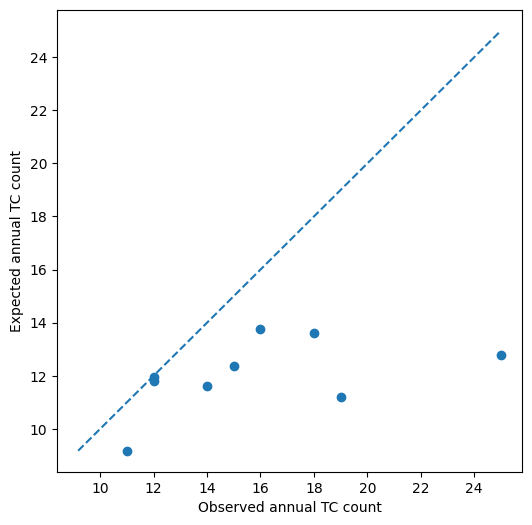

In [133]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    annual_test["observed"],
    annual_test["expected_smooth"],
)

lo = min(
    annual_test["observed"].min(),
    annual_test["expected_smooth"].min(),
)

hi = max(
    annual_test["observed"].max(),
    annual_test["expected_smooth"].max(),
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
)

ax.set_xlabel("Observed annual TC count")
ax.set_ylabel("Expected annual TC count")

plt.show()


In [53]:
def annual_variability(df, col):

    x = df[col].to_numpy()

    return {
        "mean": x.mean(),
        "std": x.std(ddof=1),
        "variance": x.var(ddof=1),
        "CV": x.std(ddof=1) / x.mean(),
    }

a = pd.DataFrame(
    {
        "observed_test": annual_variability(
            annual_test,
            "observed",
        ),
        "base_test": annual_variability(
            annual_test,
            "expected_base",
        ),
        "smooth_test": annual_variability(
            annual_test,
            "expected_smooth",
        ),
        "trend_test": annual_variability(
            annual_test,
            "expected_trend",
        ),
        "trend_bis_test": annual_variability(
            annual_test,
            "expected_trend_bis",
        ),
        "observed_train": annual_variability(
            annual_train,
            "observed",
        ),
        "base_train": annual_variability(
            annual_train,
            "expected_base",
        ),
        "smooth_train": annual_variability(
            annual_train,
            "expected_smooth",
        ),
        "trend_train": annual_variability(
            annual_train,
            "expected_trend",
        ),
        "trend_bis_train": annual_variability(
            annual_train,
            "expected_trend_bis",
        ),
    }
)
a

,observed_test,base_test,smooth_test,trend_test,trend_bis_test,observed_train,base_train,smooth_train,trend_train,trend_bis_train
mean,15.300000,11.777390,12.095084,12.037099,12.073756,11.305556,11.305556,11.305556,11.305556,11.305556
std,4.423423,1.086058,1.318597,3.415068,3.357929,4.515494,1.417330,1.540105,3.563111,3.272659
variance,19.566667,1.179522,1.738697,11.662687,11.275684,20.389683,2.008823,2.371925,12.695763,10.710298
CV,0.289113,0.092216,0.109019,0.283712,0.278118,0.399405,0.125366,0.136226,0.315165,0.289474


In [135]:
rng = np.random.default_rng(42)

N_SIM = 10_000

simulated = np.vstack(
    [
        rng.poisson(
            lam,
            size=N_SIM,
        )
        for lam in annual_test["expected_smooth"]
    ]
)


In [ ]:
FORMULA_SOFT_REGION_MONTH


glm_soft = smf.glm(
    formula=FORMULA_SOFT_REGION_MONTH,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
)

X = glm_soft.exog

s = np.linalg.svd(X, compute_uv=False)

print("n parameters:", X.shape[1])
print("rank:", np.linalg.matrix_rank(X))
print("condition number:", s[0] / s[-1])
print("smallest singular values:", s[-10:])


n parameters: 35
rank: 35
condition number: 79.50037286432932
smallest singular values: [59.73667643 59.21112268 48.4069315  42.66876876 42.66702764 42.65891658
 42.47778014 27.99351431 22.58321521 16.28166024]


In [104]:
comparison = pd.DataFrame(
    [
        evaluate_model(
            "Environmental",
            m_base,
            test_eta,
        ),
        evaluate_model(
            "Environmental + Varying",
            m_varying,
            test_eta,
        ),
        evaluate_model(
            "Environmental + PI varying",
            m_pi_varying,
            test_eta,
        ),
        evaluate_model(
            "Environmental + full varying",
            m_full_varying,
            test_eta,
        ),
        evaluate_model(
            "Environmental + Region x Month",
            m_region_month,
            test_soft,
        ),
        evaluate_model(
            "Environmental + Region Smoothed",
            m_soft_region_month,
            test_soft,
        ),
    ]
)

comparison


,model,cell_log_score,monthly_log_score,monthly_mean_log_score,monthly_bias,monthly_rmse
0,Environmental,-989.035467,-97.431665,-1.804290,-0.663761,1.643973
1,Environmental + Varying,-998.994512,-97.006342,-1.796414,-0.660954,1.622322
2,Environmental + PI varying,-988.299507,-97.249431,-1.800915,-0.656368,1.638474
3,Environmental + full varying,-1019.773843,-97.348131,-1.802743,-0.650020,1.625510
4,Environmental + Region x Month,-1097.425795,-98.447349,-1.823099,-0.632409,1.608732
5,Environmental + Region Smoothed,-974.187619,-95.628857,-1.770905,-0.624191,1.588167


In [44]:
# for name, model in {
#     "base": m_base,
#     "pi_varying": m_pi_varying,
#     "all_varying": m_varying,
#     "full_month": m_full_varying,
#     "region_month" : m_region_month,
#     "soft_region_month" : m_soft_region_month,
            
# }.items():
#     test_soft[f"mu_{name}"] = model.predict(
#         test_soft,
#         offset=test_soft["log_exposure"],
#     )


def spatial_month(df, month, column):
    d = df[df["month"] == month]

    return (
        d.groupby(
            ["latitude", "longitude"],
            as_index=False,
        )[column]
        .sum()
        .pivot(
            index="latitude",
            columns="longitude",
            values=column,
        )
    )


In [96]:
panama = test_soft["latitude"].between(8, 16) & test_soft["longitude"].between(275, 292)

diag = (
    test_soft.loc[panama]
    .groupby("month")
    .agg(
        observed=("genesis_count", "sum"),
        base=("mu_base", "sum"),
        pi_varying=("mu_pi_varying", "sum"),
        region_month=("mu_region_month", "sum"),
        soft_region_month=("mu_soft_region_month", "sum"),
        # full_varying=("mu_full_varying", "sum"),
    )
)

diag


KeyError: "Column(s) ['mu_base', 'mu_pi_varying', 'mu_region_month', 'mu_soft_region_month'] do not exist"

In [62]:
historical

,valid_time,latitude,longitude,pi,vws,rh600,eta850,w500,isobaricInhPa,time,...,mu_m1,mu_m2,contrib_z_pi,contrib_z_vws,contrib_z_rh600,contrib_z_eta850,mu_base,mu_smooth,mu_trend,mu_trend_bis
0,1980-06-01,5.5,307.5,62.214638,6.527966,74.135757,0.000012,-0.050212,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000104,0.000002,0.000003,0.000003
1,1980-06-01,5.5,308.5,64.556786,6.258497,74.159195,0.000011,-0.066386,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000134,0.000003,0.000004,0.000004
2,1980-06-01,5.5,309.5,64.749542,5.969858,74.024429,0.000011,-0.060649,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000137,0.000003,0.000003,0.000003
3,1980-06-01,5.5,310.5,65.322342,6.057087,74.127945,0.000011,-0.057414,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000143,0.000003,0.000003,0.000003
4,1980-06-01,5.5,311.5,65.222267,6.044542,73.700211,0.000011,-0.051372,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000140,0.000003,0.000003,0.000003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1014847,2025-11-01,59.5,355.5,22.557652,9.098246,50.960861,0.000050,-0.013926,500.0,2025-11-01,...,0.000059,0.000053,-1.275386,0.316850,0.384815,0.427546,0.000059,0.000043,0.000046,0.000046
1014848,2025-11-01,59.5,356.5,21.760685,9.009826,52.716721,0.000050,-0.010569,500.0,2025-11-01,...,0.000060,0.000051,-1.333020,0.323459,0.484959,0.427546,0.000060,0.000039,0.000041,0.000041
1014849,2025-11-01,59.5,357.5,21.429478,9.124449,53.687424,0.000050,-0.013743,500.0,2025-11-01,...,0.000061,0.000052,-1.356972,0.314892,0.540322,0.427546,0.000061,0.000039,0.000042,0.000042
1014850,2025-11-01,59.5,358.5,20.235909,9.368005,53.529221,0.000050,-0.019724,500.0,2025-11-01,...,0.000055,0.000050,-1.443288,0.296687,0.531299,0.427546,0.000055,0.000039,0.000042,0.000041


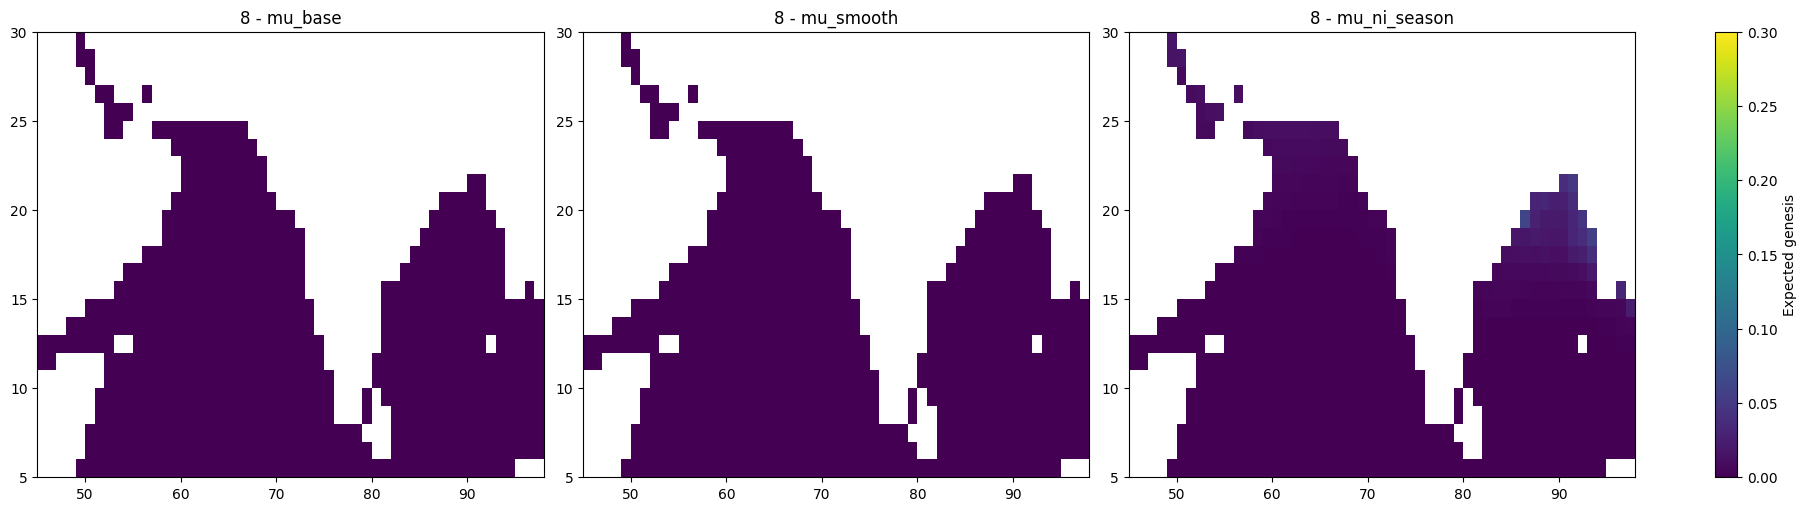

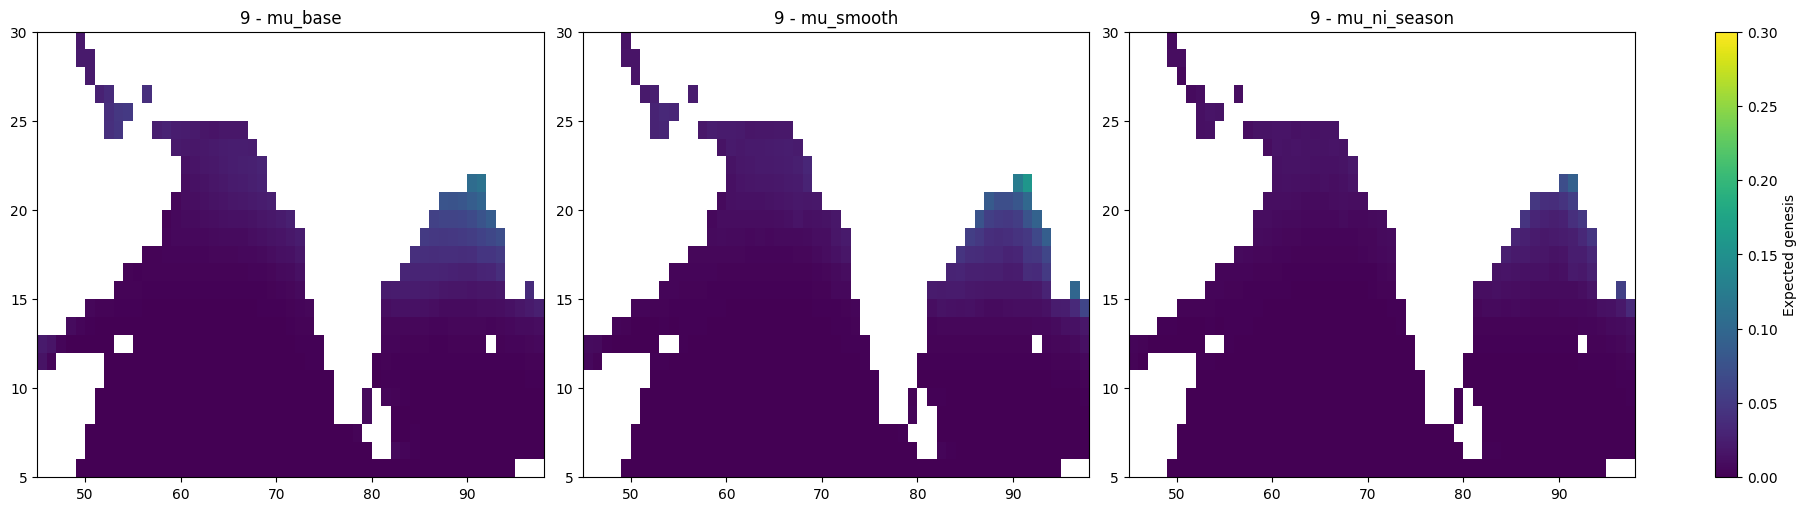

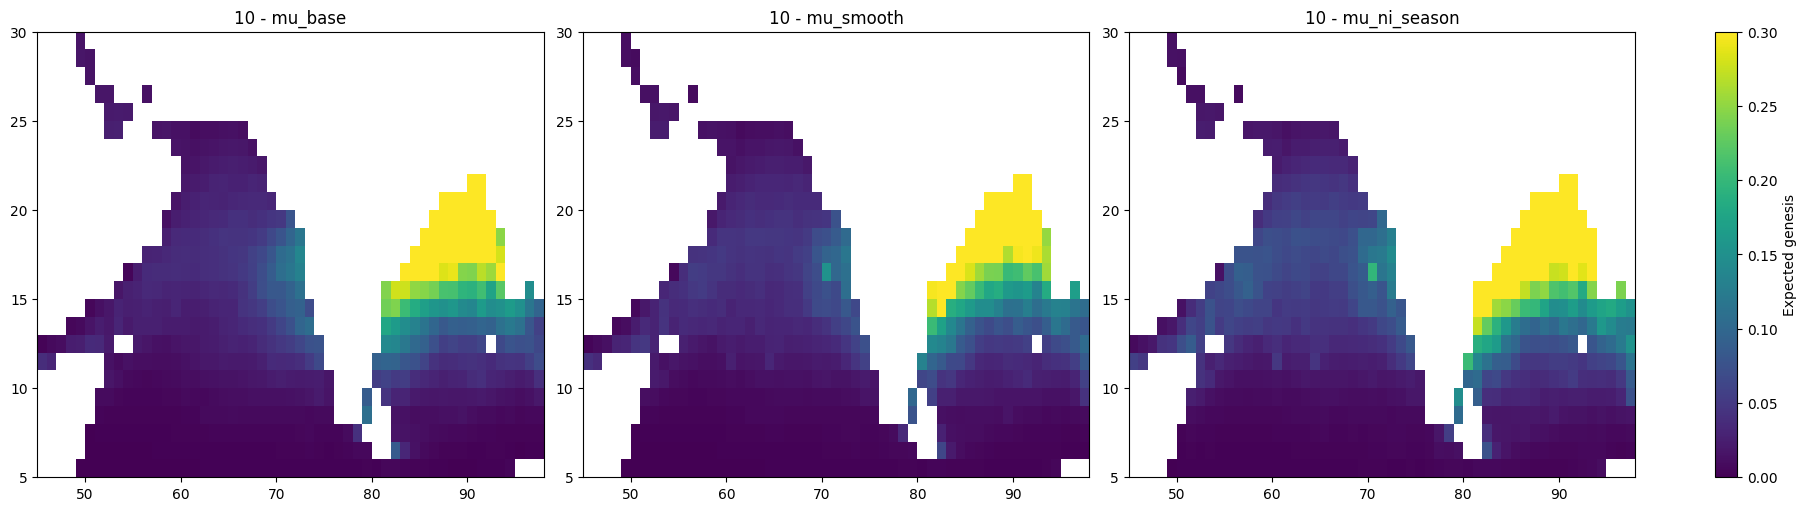

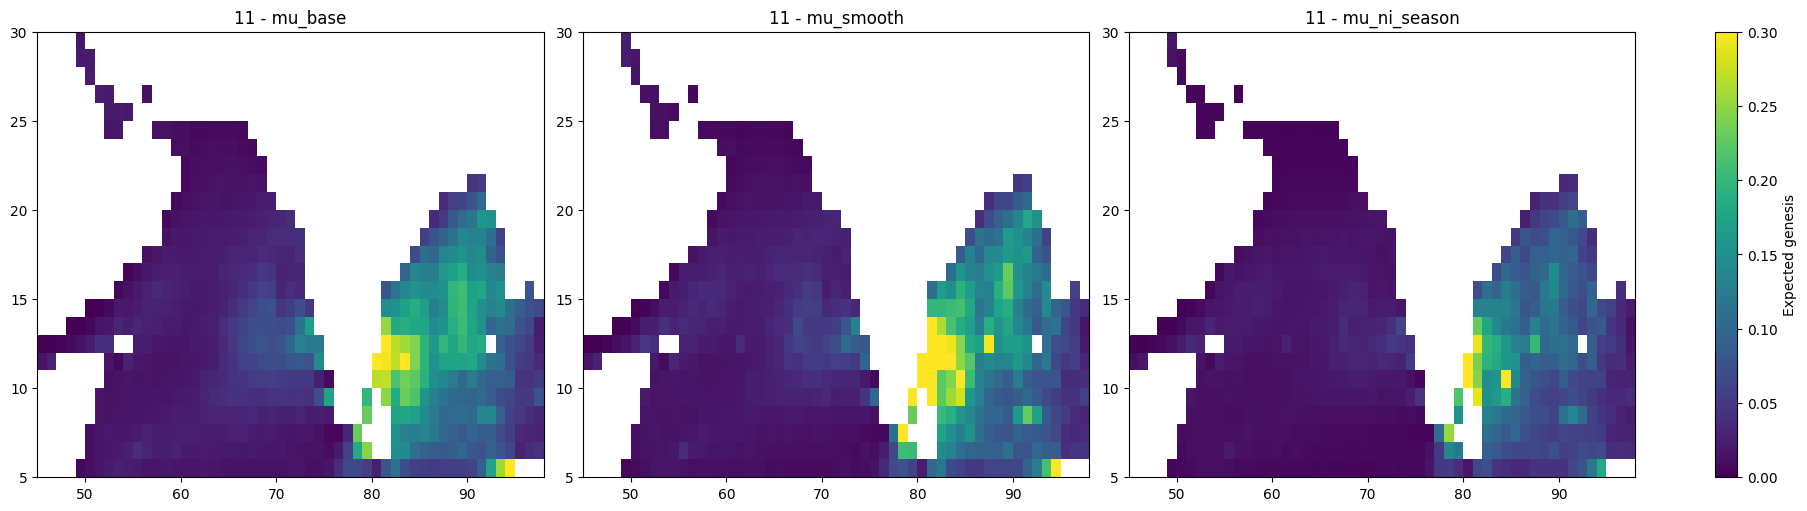

In [68]:
months = [8, 9, 10, 11]
models = [
    "mu_base",
    "mu_smooth",
    "mu_ni_season"
]

for month in months:
    fig, axes = plt.subplots(
        1,
        len(models),
        figsize=(18, 5),
        constrained_layout=True,
    )

    for ax, col in zip(axes, models):
        a = spatial_month(
            historical,
            month,
            col,
        )

        im = ax.pcolormesh(
            a.columns,
            a.index,
            a.values,
            shading="auto",
            vmin=0,
            vmax=0.3,  # adjust once, then keep common
        )

        ax.set_title(f"{month} - {col}")

    fig.colorbar(
        im,
        ax=axes,
        label="Expected genesis",
    )

    plt.show()


In [99]:
def monthly_partial_effect(
    model,
    variable,
    months=(6, 7, 8, 9, 10, 11),
    delta=0.01,
):
    rows = []

    for month in months:
        season_pos = MONTH_TO_POS[month]

        base = {
            "month": month,
            "season_pos": season_pos,
            "z_pi": 0.0,
            "z_rh600": 0.0,
            "z_vws": 0.0,
            "z_eta_clip": 0.0,
            "z_w500": 0.0,
            "log_exposure": 0.0,
        }

        low = base.copy()
        high = base.copy()

        low[variable] = -delta / 2
        high[variable] = +delta / 2

        low = pd.DataFrame([low])
        high = pd.DataFrame([high])

        loglam_low = np.log(model.predict(low, offset=[0])[0])

        loglam_high = np.log(model.predict(high, offset=[0])[0])

        beta = (loglam_high - loglam_low) / delta

        rows.append(
            {
                "month": month,
                "beta": beta,
            }
        )

    return pd.DataFrame(rows)


pi_effect = monthly_partial_effect(
    m_varying,
    "z_pi",
)

plt.plot(
    pi_effect["month"],
    pi_effect["beta"],
    marker="o",
)

plt.axhline(
    m_base.params["z_pi"],
    linestyle="--",
    label="Constant coefficient",
)

plt.ylabel(r"beta_{PI}(month)")
plt.xlabel("Month")
plt.legend()
plt.show()

NameError: name 'm_varying' is not defined

In [69]:
best_eta_threshold = eta_scores.sort_values(
    "cell_log_score",
    ascending=False,
).iloc[0]["eta_threshold"]

best_eta_model, _, best_eta_test = eta_models[best_eta_threshold]

results.append(
    evaluate_model(
        f"Eta clipped {best_eta_threshold:.2e}",
        best_eta_model,
        best_eta_test,
    )
)

comparison = (
    pd.DataFrame(results)
    .sort_values(
        "cell_log_score",
        ascending=False,
    )
    .reset_index(drop=True)
)

comparison

,model,cell_log_score,monthly_log_score,monthly_mean_log_score,monthly_bias,monthly_rmse
0,PI + Eta splines,-986.549631,-97.546567,-1.806418,-0.669056,1.635158
1,Eta clipped 3.50e-05,-989.035467,-97.431665,-1.804290,-0.663761,1.643973
2,PI spline,-990.520634,-98.151908,-1.817628,-0.683923,1.645387
3,Eta spline,-995.844365,-98.189103,-1.818317,-0.679207,1.655370
4,linear,-1007.103385,-99.453082,-1.841724,-0.684900,1.667038


## 14. Map observed and fitted genesis rates

For interpretation, aggregate expected genesis over the test interval and compare with observed genesis counts.

Normalize both to the same number of years if comparing different periods.

In [122]:
test_eta

,valid_time,latitude,longitude,pi,vws,rh600,eta850,w500,isobaricInhPa,time,...,mu_m0,mu_m1,contrib_z_pi,contrib_z_vws,contrib_z_rh600,contrib_z_eta850,mu_m2,eta_clip,z_eta_clip,region
1247410,2016-06-01,59.5,265.5,0.000000,13.311403,56.155556,0.000050,0.001333,500.0,2016-06-01,...,0.000083,0.000005,-2.906686,0.001938,0.681090,0.427546,0.000004,0.000035,0.282157,subtropical
1247411,2016-06-01,59.5,266.5,0.000000,13.461116,56.184853,0.000050,0.010244,500.0,2016-06-01,...,0.000110,0.000006,-2.906686,-0.009252,0.682761,0.427546,0.000005,0.000035,0.282157,subtropical
1247412,2016-06-01,59.5,267.5,0.000000,13.491715,56.057899,0.000050,0.006826,500.0,2016-06-01,...,0.000110,0.000006,-2.906686,-0.011539,0.675520,0.427546,0.000005,0.000035,0.282157,subtropical
1247413,2016-06-01,59.5,268.5,0.000000,13.427562,55.925087,0.000050,0.000479,500.0,2016-06-01,...,0.000110,0.000006,-2.906686,-0.006744,0.667946,0.427546,0.000005,0.000035,0.282157,subtropical
1247414,2016-06-01,59.5,269.5,0.000000,13.409151,55.198524,0.000050,0.008963,500.0,2016-06-01,...,0.000110,0.000006,-2.906686,-0.005368,0.626507,0.427546,0.000005,0.000035,0.282157,subtropical
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1559235,2024-11-01,5.5,345.5,68.177773,10.268677,58.363743,0.000012,0.013022,500.0,2024-11-01,...,0.000197,0.000109,2.023720,0.229366,0.807032,-3.262777,0.000075,0.000012,-4.558007,mdr
1559236,2024-11-01,5.5,346.5,67.703880,10.219666,57.406712,0.000011,0.009848,500.0,2024-11-01,...,0.000197,0.000090,1.989449,0.233030,0.752449,-3.365112,0.000065,0.000011,-4.781386,mdr
1559237,2024-11-01,5.5,347.5,67.302429,10.238759,56.047337,0.000010,0.003073,500.0,2024-11-01,...,0.000197,0.000073,1.960418,0.231603,0.674918,-3.464550,0.000058,0.000010,-4.998443,mdr
1559238,2024-11-01,5.5,348.5,66.955978,10.005448,54.350071,0.000009,0.000204,500.0,2024-11-01,...,0.000197,0.000057,1.935363,0.249041,0.578116,-3.607821,0.000048,0.000009,-5.311180,mdr


In [106]:
historical

,valid_time,latitude,longitude,pi,vws,rh600,eta850,w500,isobaricInhPa,time,...,mu_m1,mu_m2,contrib_z_pi,contrib_z_vws,contrib_z_rh600,contrib_z_eta850,mu_base,mu_smooth,mu_ni_season,mu_ni
0,1980-01-01,5.5,49.5,58.444386,9.110550,9.659058,0.000024,0.028449,500.0,1980-01-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000007,0.000014,0.000032,1.144858e-15
1,1980-01-01,5.5,50.5,58.195457,8.463120,10.338745,0.000021,0.030402,500.0,1980-01-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000004,0.000009,0.000022,7.497384e-16
2,1980-01-01,5.5,51.5,57.462166,8.212566,11.041870,0.000018,0.033027,500.0,1980-01-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000003,0.000006,0.000015,5.141602e-16
3,1980-01-01,5.5,52.5,57.639694,8.028523,11.965698,0.000019,0.032355,500.0,1980-01-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000004,0.000007,0.000017,5.947397e-16
4,1980-01-01,5.5,53.5,58.871353,7.874846,13.344604,0.000018,0.037055,500.0,1980-01-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000004,0.000007,0.000016,5.626586e-16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441043,2025-12-01,45.5,35.5,15.467509,8.451222,47.646038,0.000050,-0.020893,500.0,2025-12-01,...,0.000260,0.000294,-2.712328,1.290807,0.405993,2.720364,0.000260,0.000302,0.000164,3.023558e-04
441044,2025-12-01,45.5,36.5,16.018074,8.305374,49.864788,0.000050,-0.020832,500.0,2025-12-01,...,0.000321,0.000338,-2.677939,1.308403,0.505444,2.720364,0.000321,0.000345,0.000182,3.471266e-04
441045,2025-12-01,45.5,37.5,18.422194,8.322027,51.808147,0.000050,0.003399,500.0,2025-12-01,...,0.000317,0.000227,-2.527772,1.306394,0.592552,2.720364,0.000317,0.000231,0.000112,2.337338e-04
441046,2025-12-01,46.5,36.5,10.779200,8.038519,49.356976,0.000050,-0.005451,500.0,2025-12-01,...,0.000210,0.000195,-3.005169,1.340598,0.482682,2.720364,0.000210,0.000199,0.000101,1.962289e-04


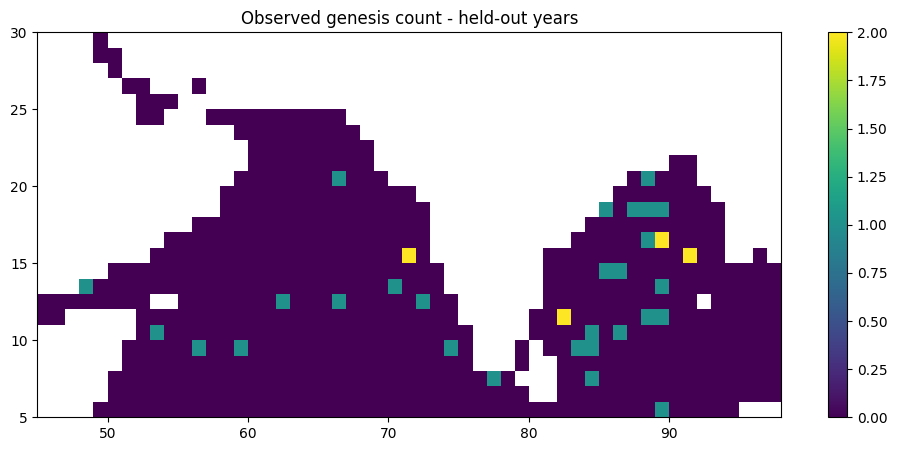

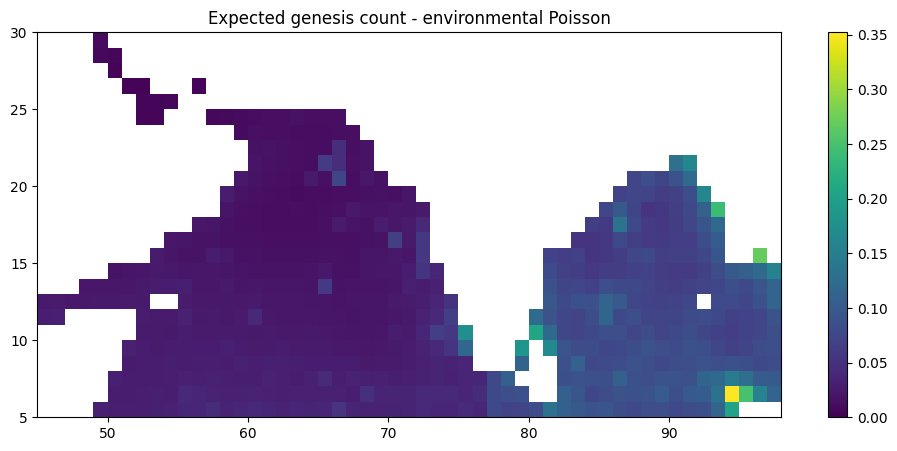

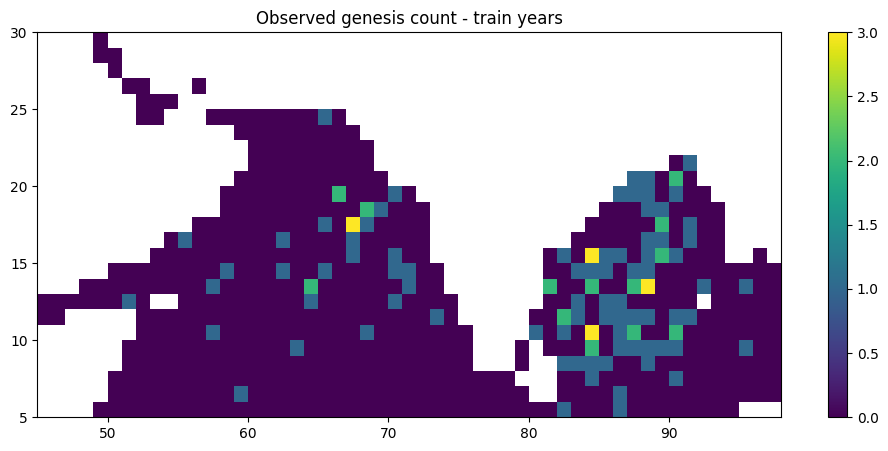

/tmp/ipykernel_23670/2444059657.py:64: UserWarning: Adding colorbar to a different Figure <Figure size 1200x500 with 3 Axes> than <Figure size 640x480 with 0 Axes> which fig.colorbar is called on.
  plt.colorbar(im, ax=ax)


<Figure size 640x480 with 0 Axes>

In [93]:
def spatial_summary(df: pd.DataFrame, mu_col: str) -> pd.DataFrame:
    return (
        df.groupby(["latitude", "longitude"], as_index=False)
        .agg(
            observed=("genesis_count", "sum"),
            expected=(mu_col, "sum"),
        )
    )


spatial = spatial_summary(historical[historical["year"] >+ CFG.first_test_year], "mu_ni_season")
#spatial_init = spatial_summary(test_soft, "mu_m1")
spatial_bis = spatial_summary(train, "genesis_count")
spatial_ter = spatial_summary(test_eta, "genesis_count")

#spatial_quat = spatial_summary(test_eta, "mu_ni_season")
#spatial_cinq = spatial_summary(test_eta, "mu_m_pi_varying")

obs = spatial.pivot(index="latitude", columns="longitude", values="observed")
obs2 = spatial_bis.pivot(index="latitude", columns="longitude", values="observed")
exp = spatial.pivot(index="latitude", columns="longitude", values="expected")
#exp_init = spatial_init.pivot(index="latitude", columns="longitude", values="expected")
#vary = spatial_quat.pivot(index="latitude", columns="longitude", values="expected")
#vary2 = spatial_cinq.pivot(index="latitude", columns="longitude", values="expected")

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(obs.columns, obs.index, obs.values, shading="auto")
ax.set_title("Observed genesis count - held-out years")
plt.colorbar(im, ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(exp.columns, exp.index, exp.values, shading="auto", vmin=0)
ax.set_title("Expected genesis count - environmental Poisson")
plt.colorbar(im, ax=ax)
plt.show()

# fig, ax = plt.subplots(figsize=(12, 5))
# im = ax.pcolormesh(
#     exp_init.columns, exp_init.index, exp_init.values, shading="auto", vmax=0.3, vmin=0
# )
# ax.set_title("Expected genesis count - environmental Poisson - init")
# plt.colorbar(im, ax=ax)
# plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(obs2.columns, obs2.index, obs2.values, shading="auto")
ax.set_title("Observed genesis count - train years")
plt.colorbar(im, ax=ax)
plt.show()


# fig, ax = plt.subplots(figsize=(12, 5))
# im = ax.pcolormesh(vary.columns, vary.index, vary.values, shading="auto", vmax=0.3, vmin=0)
# ax.set_title("Expected genesis count - environmental varying df3 Poisson")
# plt.colorbar(im, ax=ax)
# plt.show()

# fig, ax = plt.subplots(figsize=(12, 5))
# im = ax.pcolormesh(
#     vary2.columns, vary2.index, vary2.values, shading="auto", vmax=0.3, vmin=0
# )
ax.set_title("Expected genesis count - environmental varying df3 PI Poisson")
plt.colorbar(im, ax=ax)
plt.show()


In [118]:
train_soft["mu_ni_season"] = m_ni_season.predict(
    train_soft,
    offset=train_soft["log_exposure"],
)

In [119]:
check = train_soft.groupby(["region", "ni_season"], observed=True).agg(
    observed=("genesis_count", "sum"),
    expected=("mu_ni_season", "sum"),
)

check["ratio"] = check["observed"] / check["expected"]
print(check)


                            observed   expected     ratio
region        ni_season                                  
arabian_sea   monsoon              2   1.629161  1.227626
              post_monsoon        17  18.545634  0.916658
              pre_monsoon         15  13.825205  1.084975
bay_of_bengal monsoon              4   4.370839  0.915156
              post_monsoon        60  58.454366  1.026442
              pre_monsoon         23  24.174795  0.951404


In [121]:
spatial = train_soft.groupby(["latitude", "longitude"], as_index=False).agg(
    observed=("genesis_count", "sum"),
    expected=("mu_ni_season", "sum"),
)

print("Observed:", spatial["observed"].sum())
print("Expected:", spatial["expected"].sum())


Observed: 121
Expected: 121.00000000000003


In [123]:
corner = train_soft[(train_soft["longitude"] >= 94) & (train_soft["latitude"] <= 8)]

n_corner = corner["genesis_count"].sum()
mu_corner = corner["mu_ni_season"].sum()

print("Observed:", n_corner)
print("Expected:", mu_corner)

if n_corner == 0:
    print("P(N=0):", np.exp(-mu_corner))


Observed: 0
Expected: 2.381750835991042
P(N=0): 0.09238867839899946


In [127]:
diag = train_soft.copy()

zones = {
    "SE_corner": (
        (diag["longitude"] >= 94)
        & (diag["longitude"] <= 99)
        & (diag["latitude"] >= 5)
        & (diag["latitude"] <= 8)
    ),
    "BoB_core": (
        (diag["longitude"] >= 82)
        & (diag["longitude"] <= 90)
        & (diag["latitude"] >= 10)
        & (diag["latitude"] <= 18)
    ),
}

for name, mask in zones.items():
    print("\n", name)
    print(
        diag.loc[
            mask,
            [
                "pi",
                "vws",
                "eta850",
                "w500",
                "genesis_count",
            ],
        ].describe()
    )



 SE_corner
                pi          vws       eta850         w500  genesis_count
count  5184.000000  5184.000000  5184.000000  5184.000000         5184.0
mean     66.924582    15.119293     0.000015    -0.034018            0.0
std       2.443836     8.859526     0.000013     0.037863            0.0
min      57.833511     0.171239     0.000000    -0.218463            0.0
25%      65.226467     7.390988     0.000003    -0.057150            0.0
50%      66.993420    12.240849     0.000016    -0.030912            0.0
75%      68.706978    23.139176     0.000022    -0.005800            0.0
max      74.380585    36.538940     0.000050     0.042654            0.0

 BoB_core
                 pi           vws        eta850          w500  genesis_count
count  27216.000000  27216.000000  27216.000000  27216.000000   27216.000000
mean      62.635218     17.683670      0.000037     -0.012774       0.001580
std        6.169482      8.900048      0.000008      0.040194       0.039718
min       38

In [128]:
for var in ["z_pi", "z_vws", "z_eta850", "z_w500"]:
    beta = m_bob.params[var]
    train_soft[f"contrib_{var}"] = beta * train_soft[var]


In [111]:
cols = [
    "latitude",
    "longitude",
    "month",
    "z_pi",
    "z_rh600",
    "z_vws",
    "z_eta850",
    "z_w500",
    "mu_base",
    "mu_ni_season",
    "mu_ni",
    "genesis_count",
    "region",
]

hot = historical[
    (historical["longitude"] > 90) & (historical["latitude"] < 8)
][cols].copy()

hot.sort_values("mu_base", ascending=False).head(30)


,latitude,longitude,month,z_pi,z_rh600,z_vws,z_eta850,z_w500,mu_base,mu_ni_season,mu_ni,genesis_count,region
421118,5.5,94.5,12,0.275377,1.869453,-1.462719,1.140991,-1.647579,0.082276,0.020236,0.053520,0,bay_of_bengal
325238,5.5,94.5,12,0.660307,2.112714,-1.035861,1.140991,-4.560995,0.080751,0.091885,0.208568,0,bay_of_bengal
421120,5.5,96.5,12,0.425436,1.929245,-1.458534,1.140991,-1.457841,0.077975,0.015802,0.043517,0,bay_of_bengal
142267,5.5,94.5,11,0.263114,1.845646,-1.551755,1.140991,-2.294802,0.073750,0.033463,0.060890,0,bay_of_bengal
219770,5.5,94.5,12,0.597853,1.422650,-1.472609,1.140991,-0.955638,0.072399,0.016941,0.041679,0,bay_of_bengal
286886,5.5,94.5,12,0.587213,1.602910,-1.343084,1.140991,-0.567047,0.071235,0.010811,0.029641,0,bay_of_bengal
142266,5.5,93.5,11,0.258409,1.758684,-1.554590,1.140991,-2.154310,0.067903,0.030618,0.054898,0,bay_of_bengal
123093,5.5,96.5,11,0.724755,1.814065,-1.361056,1.140991,-1.411469,0.065162,0.016157,0.032565,0,bay_of_bengal
114302,5.5,94.5,12,0.413293,1.825547,-1.218390,1.140991,-1.407510,0.063679,0.013404,0.036758,0,bay_of_bengal
286888,5.5,96.5,12,0.650489,1.557072,-1.360837,1.140991,-1.152192,0.058351,0.013364,0.034101,0,bay_of_bengal


In [ ]:
historical = (
    pd.concat(
        [train_soft, test_soft],
        ignore_index=True,
    )
    .sort_values(["year", "month", "latitude", "longitude"])
    .reset_index(drop=True)
)


## 15. Fit final historical model

Only after the model form has been selected using blocked/rolling validation should the operational model be refit on the full historical period.

Do not use held-out test years to choose predictors and then report the same years as untouched validation.

In [ ]:
final_scaler = fit_standardizer(model_df, FEATURES)
final_df = apply_standardizer(model_df, final_scaler)

_, final_model = fit_poisson_models(final_df)

## 16. Forecast inference from one SEAS5 member/month

Prepare the forecast environment on exactly the same 1° grid and with the same variable definitions as ERA5.

The model produces `mu_cell`, the expected number of genesis events in each eligible cell for that forecast month.

Then:

\[
\Lambda=\sum_i \mu_i,
\qquad
N\sim Pois(\Lambda),
\qquad
p_i=\mu_i/\Lambda.
\]

In [ ]:
def build_forecast_table(
    env_month_1deg: xr.Dataset,
    coarse_exposure: xr.Dataset,
    valid_month: pd.Timestamp,
    cfg: GenesisConfig,
    scaler: dict,
) -> pd.DataFrame:
    df = (
        env_month_1deg[FEATURES]
        .to_dataframe()
        .reset_index()
    )

    exp_df = (
        coarse_exposure[
            ["eligible_area_km2", "eligible_fraction"]
        ]
        .to_dataframe()
        .reset_index()
    )

    df = df.merge(exp_df, on=["lat", "lon"], how="left")

    valid_month = pd.Timestamp(valid_month).to_period("M").to_timestamp()
    df["time"] = valid_month
    df["year"] = valid_month.year
    df["month"] = valid_month.month

    days = valid_month.days_in_month
    df["exposure"] = (
        (df["eligible_area_km2"] / cfg.area_unit_km2)
        * (days / cfg.reference_month_days)
    )

    valid = (
        (df["eligible_fraction"] >= MIN_ELIGIBLE_FRACTION)
        & (df["exposure"] > 0)
        & np.isfinite(df[FEATURES]).all(axis=1)
    )

    df = df.loc[valid].copy()
    df["log_exposure"] = np.log(df["exposure"])
    df = apply_standardizer(df, scaler)
    return df

# forecast_df = build_forecast_table(
#     seas5_member_month_1deg,
#     coarse_exposure,
#     valid_month="2026-08-01",
#     cfg=CFG,
#     scaler=final_scaler,
# )

# forecast_df["mu_cell"] = final_model.predict(
#     forecast_df,
#     offset=forecast_df["log_exposure"],
# )

## 17. Draw the monthly count and 1° genesis cells

This is the single replacement for both the current basin-frequency draw and the GPI/empirical genesis-map draw.

In [ ]:
def sample_genesis_cells(
    forecast_df: pd.DataFrame,
    rng: np.random.Generator,
    mu_col: str = "mu_cell",
) -> tuple[int, pd.DataFrame]:
    mu = np.clip(forecast_df[mu_col].to_numpy(dtype=float), 0, None)
    Lambda = mu.sum()

    if not np.isfinite(Lambda) or Lambda < 0:
        raise ValueError(f"Invalid integrated genesis rate: {Lambda}")

    n = int(rng.poisson(Lambda))
    if n == 0:
        return 0, forecast_df.iloc[0:0].copy()

    p = mu / Lambda
    chosen = rng.choice(len(forecast_df), size=n, replace=True, p=p)

    return n, forecast_df.iloc[chosen].copy().reset_index(drop=True)

# rng = np.random.default_rng(20260923)
# n, selected_cells = sample_genesis_cells(forecast_df, rng)
# print("Simulated genesis count:", n)

## 18. Uniform 0.1° ocean-constrained downscaling within a selected 1° cell

Your proposed simple downscaling is appropriate for V1.

The only change I would insist on is:

**uniform conditional on eligible ocean**, not uniform over the whole 1° square.

Procedure:

1. identify all eligible 0.1° subcells inside the selected 1° cell;
2. choose one with probability proportional to its spherical area;
3. either use its centre as the 0.1° genesis location, or jitter uniformly within the 0.1° cell.

The optional jitter below is truly area-uniform on the sphere by sampling uniformly in `sin(latitude)`.

In [ ]:
def sample_point_in_selected_cell(
    coarse_lat: float,
    coarse_lon: float,
    fine_mask: xr.Dataset,
    cfg: GenesisConfig,
    rng: np.random.Generator,
    jitter_within_fine_cell: bool = False,
) -> tuple[float, float]:
    r = int(round(cfg.coarse_res / cfg.fine_res))

    ilat = int(round((coarse_lat - (cfg.lat_min + cfg.coarse_res / 2)) / cfg.coarse_res))
    ilon = int(round((coarse_lon - (cfg.lon_min + cfg.coarse_res / 2)) / cfg.coarse_res))

    ys = slice(ilat * r, (ilat + 1) * r)
    xs = slice(ilon * r, (ilon + 1) * r)

    eligible = fine_mask["eligible"].values[ys, xs]
    area = fine_mask["fine_area_km2"].values[ys, xs]

    candidates = np.argwhere(eligible)
    if len(candidates) == 0:
        raise RuntimeError(
            f"Selected coarse cell ({coarse_lat}, {coarse_lon}) "
            "contains no eligible fine ocean cells."
        )

    weights = area[eligible].astype(float)
    weights /= weights.sum()

    k = rng.choice(len(candidates), p=weights)
    jy, jx = candidates[k]

    fine_lat_values = fine_mask["fine_lat"].values[ys]
    fine_lon_values = fine_mask["fine_lon"].values[xs]

    lat_c = float(fine_lat_values[jy])
    lon_c = float(fine_lon_values[jx])

    if not jitter_within_fine_cell:
        # Exact 0.1° output on fine-cell centres.
        return lat_c, lon_c

    half = cfg.fine_res / 2

    lat_lo = np.deg2rad(lat_c - half)
    lat_hi = np.deg2rad(lat_c + half)

    # Equal-area latitude draw on a sphere.
    sin_lat = rng.uniform(np.sin(lat_lo), np.sin(lat_hi))
    lat_out = np.rad2deg(np.arcsin(sin_lat))
    lon_out = rng.uniform(lon_c - half, lon_c + half)

    return float(lat_out), float(lon_out)


def downscale_selected_cells(
    selected_cells: pd.DataFrame,
    fine_mask: xr.Dataset,
    cfg: GenesisConfig,
    rng: np.random.Generator,
) -> pd.DataFrame:
    out = selected_cells.copy()
    points = [
        sample_point_in_selected_cell(
            row.lat,
            row.lon,
            fine_mask=fine_mask,
            cfg=cfg,
            rng=rng,
            jitter_within_fine_cell=False,
        )
        for row in out.itertuples()
    ]

    if points:
        out["genesis_lat"] = [p[0] for p in points]
        out["genesis_lon"] = [p[1] for p in points]
    else:
        out["genesis_lat"] = []
        out["genesis_lon"] = []

    return out

# simulated_genesis = downscale_selected_cells(
#     selected_cells,
#     fine_mask,
#     CFG,
#     rng,
# )

## 19. One complete forecast-month simulation function

In [ ]:
def simulate_forecast_month(
    env_month_1deg: xr.Dataset,
    valid_month,
    final_model,
    scaler,
    coarse_exposure: xr.Dataset,
    fine_mask: xr.Dataset,
    cfg: GenesisConfig,
    rng: np.random.Generator,
) -> pd.DataFrame:
    forecast_df = build_forecast_table(
        env_month_1deg=env_month_1deg,
        coarse_exposure=coarse_exposure,
        valid_month=pd.Timestamp(valid_month),
        cfg=cfg,
        scaler=scaler,
    )

    forecast_df["mu_cell"] = final_model.predict(
        forecast_df,
        offset=forecast_df["log_exposure"],
    )

    _, selected = sample_genesis_cells(
        forecast_df,
        rng=rng,
        mu_col="mu_cell",
    )

    return downscale_selected_cells(
        selected,
        fine_mask=fine_mask,
        cfg=cfg,
        rng=rng,
    )

## 20. Sensitivity experiments before accepting the model

The following are more important than adding a complicated spatial random field.

### Resolution
Repeat the complete fit at:

- 0.5°
- 1°
- 2°

and compare held-out:

- basin-month Poisson log score;
- spatial cell log likelihood;
- integrated annual count bias;
- genesis density maps;
- downstream track/landfall differences.

The expectation is that 1° and 2° will often be close. Use the experiment to justify the choice rather than assuming it.

### Environmental specification
Compare at least:

- M0: month only;
- M1: month + PI + RH + VWS + absolute vorticity;
- M2: M1 with saturating/nonlinear vorticity;
- M3: selected GAM/spline effects if M2 leaves strong nonlinear residuals;
- current phase-frequency + GPI-MIX baseline.

### Distribution
Start with Poisson. Escalate only if held-out aggregate counts show persistent conditional overdispersion.

### Validation
Use blocked or rolling years. Never choose the model from random cell-row cross-validation.

## 21. Recommended next notebook

Once this linear Poisson version is stable, the next notebook should answer only one question:

**Do nonlinear environmental response functions materially improve held-out count and spatial-genesis skill?**

That notebook can compare:

- linear GLM;
- capped/saturating vorticity;
- physically motivated transforms;
- GAM splines;
- PI vs relative SST vs ventilated PI.

Do not add clustering, negative-binomial dispersion, climate indices, or a latent process until the basic environmental rate model has been validated.